<a href="https://colab.research.google.com/github/Olya-Shulga/Univercity/blob/main/data_mining/%D0%9F%D1%80%D0%B0%D0%BA%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B0%D1%8F_%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0_%E2%84%963_%D0%A1%D1%80%D0%B0%D0%B2%D0%BD%D0%B8%D1%82%D0%B5%D0%BB%D1%8C%D0%BD%D1%8B%D0%B9_%D0%B0%D0%BD%D0%B0%D0%BB%D0%B8%D0%B7_%D0%B1%D0%B0%D0%B7%D0%BE%D0%B2%D1%8B%D1%85_%D0%B8_%D0%B0%D0%BD%D1%81%D0%B0%D0%BC%D0%B1%D0%BB%D0%B5%D0%B2%D1%8B%D1%85_%D0%BC%D0%B5%D1%82%D0%BE%D0%B4%D0%BE%D0%B2_%D0%BC%D0%B0%D1%88%D0%B8%D0%BD%D0%BD%D0%BE%D0%B3%D0%BE_%D0%BE%D0%B1%D1%83%D1%87%D0%B5%D0%BD%D0%B8%D1%8F_%D0%B2_%D0%B7%D0%B0%D0%B4%D0%B0%D1%87%D0%B0%D1%85_%D0%BA%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D0%B8_%D1%82%D0%B5%D0%BA%D1%81%D1%82%D0%BE%D0%B2_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Практическая работа №3. Сравнительный анализ базовых и ансамблевых методов машинного обучения в задачах классификации текстов**

---

## **Введение**

Отзывы об организациях содержат два источника информации: текст с описанием опыта посетителя и оценку от 1 до 5 звёзд. Их сопоставление позволяет выявить случаи, требующие подробного анализа: неоднозначные тексты, расхождения между содержанием и оценкой, а также ошибки моделей.

Методы классификации текстов применяются для определения тональности и прогнозирования оценки по содержанию отзыва. Результаты объединяются со сведениями об организациях и их координатами, чтобы сравнить отзывы выбранных территорий и отобразить выявленные расхождения на карте.

**🎯 Цель работы:** освоить построение и оценку моделей классификации русскоязычных текстов и применить их к анализу отзывов об организациях с учётом пространственного расположения объектов.

**Задачи работы:**

1. Подготовить текстовые данные и сравнить мешок слов, TF-IDF, Word2Vec, Doc2Vec и современные нейросетевые эмбеддинги.
2. Обучить и сравнить классификаторы тональности, подобрать параметры и оценить качество на тестовой выборке.
3. Построить модель прогнозирования оценки по тексту отзыва с разделением данных по организациям.
4. Сформулировать правило отбора отзывов, в которых текст может расходиться с оценкой, и проверить его по результатам чтения.
5. Собрать отзывы выбранных территорий, подготовить сводку по организациям и карты тональности, оценок и расхождений.
6. Сравнить результаты для двух территорий и сформулировать выводы с учётом качества моделей и ограничений выборки.

**Данные:**

- [RuSentiTweet](https://github.com/sismetanin/rusentitweet) — русскоязычные сообщения с разметкой тональности;
- [Geo Reviews Dataset 2023](https://github.com/yandex/geo-reviews-dataset-2023) — отзывы об организациях с оценками от 1 до 5;
- свежие отзывы выбранной территории, которые вы соберёте [сборщиком отзывов Яндекс Карт](https://github.com/Alexandre77777/yandex-maps-reviews).

**Структура работы:**

| Часть | Вопрос исследования | Результат |
|---|---|---|
| 1. Тональность текста | Какое представление текста и какой классификатор позволяют точнее определить тональность? | Модель тональности и сравнение методов |
| 2. Оценка по тексту | Насколько точно можно предсказать оценку и как отобрать расхождения между текстом и звёздами? | Модель оценки, правило отбора и опорная частота расхождений |
| 3. Анализ территорий | Какие расхождения встречаются в собранных отзывах и различаются ли территории? | Проверенные примеры, сводка по организациям, карты и сравнение двух территорий |

> 📝 **Как выполнять работу.** Выполняйте ячейки сверху вниз. В ячейках `# ВАШ КОД` напишите своё решение; в некоторых из них уже есть заготовка — замените многоточия. Чтобы ответить на вопрос, дважды щёлкните по ячейке «Ответ», впишите текст и нажмите `Shift+Enter`.

---

## **Часть 0. Настройка окружения**

Откройте блокнот в Colab и включите видеокарту: **Среда выполнения → Сменить среду выполнения → GPU**. Затем установите библиотеки и выполните импорты.

In [1]:
# Устанавливаем библиотеки для векторизации, классификации и карт.
%pip install -q scikit-learn==1.7.2 gensim==4.4.0 lightgbm==4.7.0 sentence-transformers==5.2.0 transformers==4.57.6 pyarrow geopandas folium osmnx==2.1.0

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import os  # Задаём число вычислительных потоков.
from pathlib import Path  # Работаем с путями к файлам.
THREADS = min(6, os.cpu_count() or 1)  # Используем не больше доступного числа процессоров.
os.environ['OMP_NUM_THREADS'] = str(THREADS)  # Ограничиваем потоки вычислительных библиотек.
os.environ['MKL_NUM_THREADS'] = str(THREADS)  # Согласуем потоки линейной алгебры.

import numpy as np  # Работаем с массивами.
import pandas as pd  # Работаем с таблицами.
import matplotlib.pyplot as plt  # Строим графики.
import seaborn as sns  # Показываем распределения и матрицы ошибок.
import torch  # Проверяем доступность видеокарты.
from IPython.display import display  # Выводим таблицы и карты.

SEED = 42  # Фиксируем случайность разделений и обучения.
np.random.seed(SEED)  # Повторяем случайный выбор примеров.
torch.set_num_threads(THREADS)  # Ограничиваем потоки PyTorch.
device = 'cuda' if torch.cuda.is_available() else 'cpu'  # Выбираем устройство для эмбеддингов.
pd.set_option('display.max_colwidth', None)  # Показываем тексты целиком.
plt.rcParams['figure.figsize'] = (9, 4)  # Задаём размер графиков.
print('Устройство:', device)  # Проверяем, подключена ли видеокарта.

Устройство: cuda


> **18+.** Пользовательские тексты могут содержать ненормативную лексику. Для просмотра таблиц с текстами используйте функцию `show(...)`: она заменяет такие слова на `[скрыто]` только при показе, а данные для обучения не меняет.

In [3]:
# Готовая функция для вывода текстов
import base64, gzip, re  # Подключаем средства чтения встроенных правил.
display_pattern = re.compile(gzip.decompress(base64.b64decode('H4sIAAAAAAACCl1QMQ7CMBB7CxvwBBYeknYpEgIxAmK5oVAhNhA/CSKBQmn5gu9HOEknFut8d7F9yYrhdDCcTmDR6p74wQ2NsGy0wgOetBV80elBy0g5rf4aJHu8iWWiqbRpueR67Lq+iD5pFN97OqRSr8Gs6bsuCiU6ynbjrAjIsHrUyuAFr1e9oNZzzoQGNXyOJ5+ZMMlx6+8SWD0QQoZWK8bXU3DpAtQEvQiVuOIjoB1JyGcoTkUXCXeobeO3fIXfRGE4WMG9L7vg9OHYGXa6HG+Zb2crWS+WGymWm9kiHfED+6yyw3MBAAA=')).decode('utf-8'), re.IGNORECASE)  # Подготавливаем фильтр.
def show(frame):  # Маскируем текст только в отображаемой копии.
    shown = frame.to_frame() if isinstance(frame, pd.Series) else frame.copy()  # Сохраняем исходные значения.
    for column in shown.select_dtypes(include=['object','string']):  # Обрабатываем текстовые поля.
        shown[column] = shown[column].astype(str).str.replace(display_pattern,'[скрыто]',regex=True)  # Скрываем совпадения.
    display(shown)  # Показываем подготовленную таблицу.

---

## **Часть 1. Тональность текста**

**Задача:** по тексту сообщения определить его тональность — отрицательную, нейтральную или положительную.

**Датасет:** [RuSentiTweet](https://github.com/sismetanin/rusentitweet) содержит русскоязычные сообщения социальной сети, размеченные по тональности. В корпусе есть обучающая и тестовая части. Тестовую часть оставим для итоговой проверки, а из обучающей выделим валидацию для выбора моделей и параметров.

Обученная модель понадобится в частях 2 и 3: она станет первым «читателем» отзывов.

### **1.1. Загрузка и первичный осмотр данных**

> 📚 **Подсказка:** Загрузка корпуса и чтение CSV показаны в [**Теории №7**](https://colab.research.google.com/github/Alexandre77777/data_mining/blob/main/5.%20%D0%9A%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D1%8F%20%D1%82%D0%B5%D0%BA%D1%81%D1%82%D0%BE%D0%B2.%20%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%20%D0%9D%D0%B0%D0%B8%D0%B2%D0%BD%D0%BE%D0%B3%D0%BE%20%D0%91%D0%B0%D0%B9%D0%B5%D1%81%D0%B0.%20%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%20%D0%BE%D0%BF%D0%BE%D1%80%D0%BD%D1%8B%D1%85%20%D0%B2%D0%B5%D0%BA%D1%82%D0%BE%D1%80%D0%BE%D0%B2/%D0%A2%D0%B5%D0%BE%D1%80%D0%B8%D1%8F/%D0%A2%D0%B5%D0%BE%D1%80%D0%B8%D1%8F_%E2%84%967_%D0%9F%D1%80%D0%B8%D0%BC%D0%B5%D0%BD%D0%B5%D0%BD%D0%B8%D0%B5_%D0%BC%D0%B5%D1%82%D0%BE%D0%B4%D0%BE%D0%B2_%D0%BC%D0%B0%D1%88%D0%B8%D0%BD%D0%BD%D0%BE%D0%B3%D0%BE_%D0%BE%D0%B1%D1%83%D1%87%D0%B5%D0%BD%D0%B8%D1%8F_%D0%B4%D0%BB%D1%8F_%D1%80%D0%B5%D1%88%D0%B5%D0%BD%D0%B8%D1%8F_%D0%B7%D0%B0%D0%B4%D0%B0%D1%87%D0%B8_%D0%BA%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D0%B8_%D1%82%D0%B5%D0%BA%D1%81%D1%82%D0%BE%D0%B2.ipynb#scrollTo=hJVEXL-bcVRg).

In [4]:
if not Path('rusentitweet').exists():  # При повторном запуске используем уже скачанную папку.
    !git clone -q --depth 1 https://github.com/sismetanin/rusentitweet.git rusentitweet
train_source = pd.read_csv('rusentitweet/rusentitweet_train.csv')  # Читаем обучающую часть.
test_source = pd.read_csv('rusentitweet/rusentitweet_test.csv')  # Читаем тестовую часть.
show(train_source.head())  # Смотрим столбцы и примеры.

,text,label,id
0,Помойму я вкрашилась в Чимина🤧 https://t.co/t2uZTS7NH2,positive,1282311169534038016
1,@namaskaramsaroo Мотоцикль,neutral,1272864221202530309
2,Михаил Мишустин: меры по борьбе с коронавирусом в России были своевременные и правильные https://t.co/bYMCUoZDMk,neutral,1296860899739947008
3,@bbsbro_ доброй ноченьки 💕,speech,1288168112425246721
4,ну что пойду чекну фоточки,neutral,1287678712612364288


**1. Выведите размеры обучающей и тестовой частей, число пропусков и количество примеров каждой исходной метки.**

In [5]:

# 1. Размеры обучающей и тестовой выборок
print("Размеры выборок:")
print(f"Обучающая: {train_source.shape[0]} строк, {train_source.shape[1]} столбцов")
print(f"Тестовая: {test_source.shape[0]} строк, {test_source.shape[1]} столбцов")

# 2. Проверка пропущенных значений
print("\nПропущенные значения в обучающей выборке:")
print(train_source.isna().sum())

print("\nПропущенные значения в тестовой выборке:")
print(test_source.isna().sum())

# 3. Распределение исходных меток
print("\nРаспределение классов в обучающей выборке:")
print(train_source["label"].value_counts().to_string())

print("\nРаспределение классов в тестовой выборке:")
print(test_source["label"].value_counts().to_string())

# 4. Доли классов в обучающей выборке
print("\nДоли классов в обучающей выборке (%):")
print(
    train_source["label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .to_string()
)


Размеры выборок:
Обучающая: 10713 строк, 3 столбцов
Тестовая: 2679 строк, 3 столбцов

Пропущенные значения в обучающей выборке:
text     0
label    0
id       0
dtype: int64

Пропущенные значения в тестовой выборке:
text     0
label    0
id       0
dtype: int64

Распределение классов в обучающей выборке:
label
neutral     4273
negative    2638
positive    1931
skip        1474
speech       397

Распределение классов в тестовой выборке:
label
neutral     1068
negative     660
positive     483
skip         369
speech        99

Доли классов в обучающей выборке (%):
label
neutral     39.89
negative    24.62
positive    18.02
skip        13.76
speech       3.71


**2. Покажите по три случайных текста классов `negative`, `neutral` и `positive`.**

In [6]:
# Выбираем по три случайных сообщения каждого класса
sentiment_classes = ["negative", "neutral", "positive"]

for sentiment in sentiment_classes:
    examples = train_source.loc[
        train_source["label"] == sentiment,
        ["text", "label"]
    ].sample(n=3, random_state=SEED)

    print(f"\nПримеры класса: {sentiment}")
    show(examples.reset_index(drop=True))



Примеры класса: negative


,text,label
0,Максимально допустимая продолжительность видео — 2 минуты 20 секунд.\r\n\r\nО нет.....,negative
1,опять ошибки да ок понятно тупица м,negative
2,@chern_ov Мне самой кажется эстетичным носы с горбинкой\r\nНо свой из за неё я буквально ненавижу\r\n¯\_༼ •́ ͜ʖ •̀ ༽_/¯,negative



Примеры класса: neutral


,text,label
0,"Правильно пишется ""Конституции""",neutral
1,@shkolar92 Так я ж не парней с видео имел ввиду. Ты наверно не совсем понял этот твит),neutral
2,@ybudyan @SkunkAngry @Alex_zhzhet Квартира в наследство досталась.,neutral



Примеры класса: positive


,text,label
0,хорошо мой павелитель 🙏🏻 https://t.co/pNYA8ucoYw,positive
1,@JoomOfficialRu вроде смешно https://t.co/Oo3uOblGSb,positive
2,Ничего необычного) 😂 https://t.co/mYrxsYTtmX,positive


**Как читать разметку.** `positive` и `negative` — выраженная положительная или отрицательная оценка; `neutral` — содержательное сообщение без выраженной оценки. `speech` обозначает речевые акты (приветствие, поздравление), `skip` — сообщения, тональность которых определить трудно. В работе используем первые три класса. [Описание корпуса](https://github.com/sismetanin/rusentitweet).

**Вопрос:** Сколько примеров каждого из трёх используемых классов в обучающей части? Почему классы `speech` и `skip` не объединяем с `neutral`?

**Ответ:** В обучающей выборке представлено 4273 нейтральных, 2638 отрицательных и 1931 положительное сообщение. Наиболее многочисленным является класс `neutral`, поэтому распределение данных нельзя назвать полностью сбалансированным.

Классы `speech` и `skip` не объединяются с нейтральными сообщениями, поскольку имеют другое значение. Класс `speech` содержит речевые действия, например приветствия и поздравления, а `skip` объединяет сообщения, для которых затруднительно определить тональность. Нейтральный класс, в отличие от них, предполагает отсутствие выраженной положительной или отрицательной оценки. Объединение этих категорий сделало бы разметку менее однозначной и могло отрицательно повлиять на обучение классификатора.

---

### **1.2. Очистка и разделение данных**

Один и тот же текст не должен встречаться в нескольких частях: иначе итоговая проверка частично измеряла бы запоминание. Для поиска повторов создаём ключ — текст без различий регистра и пробелов. Повторы с разными метками удаляем как противоречивые. Исходный текст сохраняем для признаков и чтения.

In [7]:
from sklearn.model_selection import train_test_split  # Выделяем валидацию.

def text_key(column):  # Ключ для поиска одинаковых текстов.
    return column.fillna('').astype(str).str.normalize('NFKC').str.replace(r'\s+', ' ', regex=True).str.strip().str.casefold()  # Убираем различия регистра и пробелов.

labels = ['negative', 'neutral', 'positive']  # Три целевых класса.
prepared = {}  # Подготовленные исходные части.
for name, frame in [('train', train_source), ('test', test_source)]:  # Обрабатываем обе части одинаково.
    frame = frame.copy()  # Не меняем исходную таблицу.
    frame['text_key'] = text_key(frame.text)  # Ключ каждого текста.
    conflict = frame.groupby('text_key').label.transform('nunique').gt(1)  # Одинаковые тексты с разными метками.
    keep = frame.label.isin(labels) & frame.text_key.ne('') & ~conflict  # Пригодные записи.
    prepared[name] = frame.loc[keep].drop_duplicates('text_key').reset_index(drop=True)  # Удаляем повторы.

test = prepared['test']  # Итоговая проверка.
development = prepared['train'].loc[~prepared['train'].text_key.isin(test.text_key)]  # Убираем из обучения тексты теста.
train, valid = train_test_split(development, test_size=0.2, stratify=development.label, random_state=SEED)  # Сохраняем доли классов.
train, valid = train.reset_index(drop=True), valid.reset_index(drop=True)  # Последовательные индексы.

**Выведите численность классов в `train`, `valid` и `test` и проверьте, что ни одна пара частей не имеет общих текстов (по столбцу `text_key`).**

<details>
<summary><b>Пример кода</b></summary>

```python
show(pd.DataFrame({'train': train.label.value_counts(), 'valid': valid.label.value_counts()}))
print('train / valid:', len(set(train.text_key) & set(valid.text_key)))
```

</details>

In [8]:
# Сравниваем распределение классов в трёх выборках
class_distribution = pd.DataFrame({
    "Обучающая": train["label"].value_counts(),
    "Валидационная": valid["label"].value_counts(),
    "Тестовая": test["label"].value_counts()
}).fillna(0).astype(int)

print("Распределение классов:")
display(class_distribution)

print("\nКоличество записей:")
for name, dataset in [
    ("train", train),
    ("valid", valid),
    ("test", test)
]:
    print(f"{name}: {len(dataset)}")

# Проверяем пересечение текстов между выборками
datasets = {"train": train, "valid": valid, "test": test}

print("\nПроверка повторяющихся текстов:")

from itertools import combinations

for (name1, data1), (name2, data2) in combinations(datasets.items(), 2):
    common = set(data1["text_key"]) & set(data2["text_key"])
    print(f"{name1} / {name2}: {len(common)} совпадений")


Распределение классов:


,Обучающая,Валидационная,Тестовая
label,,,
neutral,3418,855,1068
negative,2110,528,660
positive,1545,386,483



Количество записей:
train: 7073
valid: 1769
test: 2211

Проверка повторяющихся текстов:
train / valid: 0 совпадений
train / test: 0 совпадений
valid / test: 0 совпадений


> 📚 **Подсказка:** train нужен для обучения, valid — для выбора модели и параметров, test — для итоговой оценки после выбора. [**Разделение данных и кросс-валидация**](https://colab.research.google.com/drive/1xSmltveF3hdM-Hf6tDO88ME7zqQAu0MT#scrollTo=hc87mctOPspb).

**Вопрос:** Зачем нужна валидация, если в корпусе уже есть тестовая часть?

**Ответ:** Валидационная выборка необходима для промежуточной проверки модели во время разработки. По результатам валидации можно сравнивать алгоритмы, изменять гиперпараметры и выбирать наиболее подходящий вариант.

Тестовая выборка предназначена для независимой оценки уже выбранной модели. Если использовать её при каждой настройке, модель может оказаться косвенно подстроенной под тестовые данные, а полученная оценка качества будет слишком оптимистичной.

Таким образом, разделение данных на три части позволяет отдельно проводить обучение, настройку и окончательную проверку модели.

---

### **1.3. Разведочный анализ и гипотезы**

> 📚 **Подсказка:** [**Занятие 2: распределение классов**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan#scrollTo=15c684d7); [**Macro-F1**](https://colab.research.google.com/drive/1P5GxyckR2Bb5clpEs2EflKo1JU7D5ULu#scrollTo=0c5d5827).

**1. Постройте распределение классов в обучающей части.**

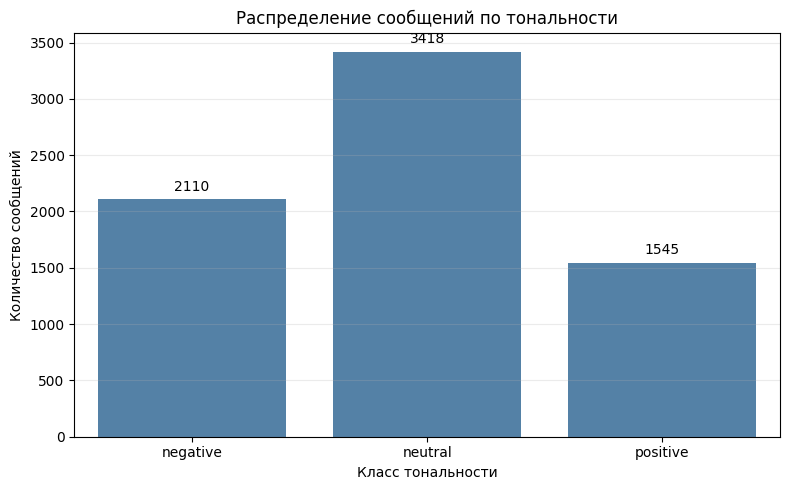

In [11]:
# Визуализация количества сообщений разных классов
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=train,
    x="label",
    order=labels,
    color="steelblue"
)

for container in ax.containers:
    ax.bar_label(container, padding=4)

plt.title("Распределение сообщений по тональности")
plt.xlabel("Класс тональности")
plt.ylabel("Количество сообщений")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


**2. Сравните длину текстов (в символах) по классам с помощью `boxplot`.**

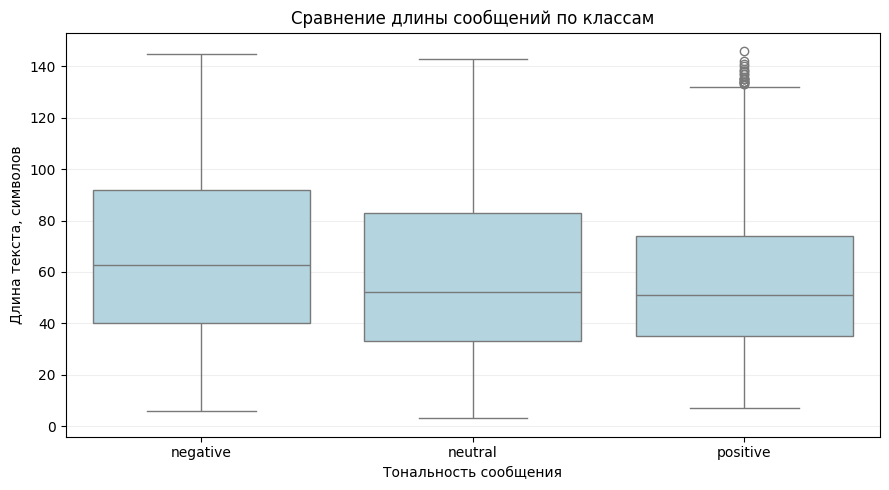

Статистика длины сообщений:


,mean,median,min,max
label,,,,
negative,67.8,62.5,6,145
neutral,59.5,52.0,3,143
positive,57.7,51.0,7,146


In [10]:
# Создаём признак длины сообщения
train["text_length"] = train["text"].str.len()

# Сравниваем распределение длин для разных классов
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=train,
    x="label",
    y="text_length",
    order=labels,
    color="lightblue"
)

plt.title("Сравнение длины сообщений по классам")
plt.xlabel("Тональность сообщения")
plt.ylabel("Длина текста, символов")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

# Дополнительно вычисляем статистики
print("Статистика длины сообщений:")
display(
    train.groupby("label")["text_length"]
    .agg(["mean", "median", "min", "max"])
    .round(1)
)


Чтобы гипотезы о признаках были осмысленными, сравните способы представления текста, которые будут использованы дальше:

| Представление | Что описывает вектор текста | Обучается на наших данных? |
|---|---|---|
| BoW (мешок слов) | Частоты слов и пар соседних слов | Словарь — да |
| TF-IDF | Те же частоты, взвешенные по редкости слова в обучающих текстах | Словарь и веса — да |
| Средний Word2Vec | Среднее векторов слов текста | Да |
| Doc2Vec | Вектор документа, выведенный обученной моделью | Да |
| E5, Giga | Вектор текста из готовой нейросети, учитывающей контекст слов | Нет, веса готовые |

Главная метрика сравнения — **macro-F1**: среднее F1 по трём классам, где каждый класс имеет одинаковый вес. Дополнительно смотрим accuracy и время обучения.

Сформулируйте **две гипотезы**: одну о представлении текста, другую — о классификаторе или учёте дисбаланса классов. Для каждой укажите наблюдение или теоретическое соображение, ожидаемое изменение macro-F1 и способ проверки.

| № | Наблюдение или соображение | Гипотеза | Как проверить |
|---|---|---|---|
| 1 | ... | ... | ... |
| 2 | ... | ... | ... |

<details>
<summary><b>Подсказка к формулировке гипотез</b></summary>

Мешок слов хранит частоты отдельных слов и, при `ngram_range=(1, 2)`, соседних пар. Пара «не понравилось» может войти в словарь, но порядок всего предложения и близость синонимов такое представление не описывает. Какое представление может учесть больше контекста и для какого классификатора это окажется полезным? Посмотрите на распределение классов: как самый частый класс повлияет на accuracy постоянного прогноза?

Пример гипотезы: «На эмбеддингах E5 SVM получит macro-F1 выше, чем на TF-IDF, потому что вектор E5 учитывает контекст; проверим по таблице сравнения».

</details>

**Гипотезы:**

| № | Наблюдение или соображение | Гипотеза | Как проверить |
|---|---|---|---|
| 1 | Отрицательные сообщения в среднем длиннее положительных (67,8 против 57,7 символа). При этом длины текстов разных классов сильно пересекаются, поэтому одной длины недостаточно для определения тональности. | TF-IDF позволит получить более высокий macro-F1, чем BoW, поскольку учитывает не только частоту слов, но и их информативность. | Обучить одинаковый классификатор на BoW и TF-IDF, сравнить macro-F1 на валидационной выборке. |
| 2 | В обучающей выборке преобладают нейтральные сообщения (3418), тогда как положительных значительно меньше (1545). Из-за этого модель может чаще предсказывать самый распространённый класс. | Использование сбалансированных весов классов (`class_weight='balanced'`) повысит macro-F1 по сравнению с обучением без весов, так как модель будет уделять больше внимания менее представленным классам. | Обучить один классификатор с обычными и сбалансированными весами, затем сравнить macro-F1 и F1 каждого класса на валидационной выборке. |

**Вопрос:** Почему при таком распределении классов нельзя выбирать модель только по accuracy?

**Ответ:** В исследуемом наборе данных количество сообщений разных классов заметно отличается. Нейтральные сообщения составляют почти половину обучающей выборки, тогда как положительных значительно меньше.

Метрика accuracy показывает общую долю правильных предсказаний, но не учитывает, насколько хорошо модель распознаёт каждый класс по отдельности. Например, если классификатор будет относить все сообщения к нейтральным, он получит accuracy около 48%, хотя фактически не сможет определять положительную и отрицательную тональность.

Поэтому при сравнении моделей целесообразно использовать macro-F1. Эта метрика вычисляет F1 отдельно для каждого класса, а затем усредняет результаты. Таким образом, качество распознавания менее распространённых классов будет учитываться наравне с наиболее многочисленным.

---

### **1.4. Мешок слов и TF-IDF**

> 📚 **Подсказка:** Построение мешка слов и TF-IDF показано в [**Теории №7**](https://colab.research.google.com/github/Alexandre77777/data_mining/blob/main/5.%20%D0%9A%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D1%8F%20%D1%82%D0%B5%D0%BA%D1%81%D1%82%D0%BE%D0%B2.%20%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%20%D0%9D%D0%B0%D0%B8%D0%B2%D0%BD%D0%BE%D0%B3%D0%BE%20%D0%91%D0%B0%D0%B9%D0%B5%D1%81%D0%B0.%20%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%20%D0%BE%D0%BF%D0%BE%D1%80%D0%BD%D1%8B%D1%85%20%D0%B2%D0%B5%D0%BA%D1%82%D0%BE%D1%80%D0%BE%D0%B2/%D0%A2%D0%B5%D0%BE%D1%80%D0%B8%D1%8F/%D0%A2%D0%B5%D0%BE%D1%80%D0%B8%D1%8F_%E2%84%967_%D0%9F%D1%80%D0%B8%D0%BC%D0%B5%D0%BD%D0%B5%D0%BD%D0%B8%D0%B5_%D0%BC%D0%B5%D1%82%D0%BE%D0%B4%D0%BE%D0%B2_%D0%BC%D0%B0%D1%88%D0%B8%D0%BD%D0%BD%D0%BE%D0%B3%D0%BE_%D0%BE%D0%B1%D1%83%D1%87%D0%B5%D0%BD%D0%B8%D1%8F_%D0%B4%D0%BB%D1%8F_%D1%80%D0%B5%D1%88%D0%B5%D0%BD%D0%B8%D1%8F_%D0%B7%D0%B0%D0%B4%D0%B0%D1%87%D0%B8_%D0%BA%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D0%B8_%D1%82%D0%B5%D0%BA%D1%81%D1%82%D0%BE%D0%B2.ipynb#scrollTo=9jTeKixplgYk). Сравните методы `fit_transform` и `transform`.

Мешок слов превращает текст в частоты слов и соседних пар: каждому элементу словаря соответствует столбец матрицы. TF-IDF изменит веса этих частот, чтобы отличать распространённые слова от более редких.

Словарь и веса строим **только по обучающей части**. Валидацию и тест преобразуем теми же объектами методом `transform`: иначе одинаковые столбцы могут обозначать разные слова.

**1. Создайте `bow = CountVectorizer(ngram_range=(1, 2), min_df=2, max_features=20000, dtype=np.float64)` и получите `X_bow_train`, `X_bow_valid`, `X_bow_test`.**

In [12]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer  # Словарные признаки.

# Создаём векторизатор для слов и пар слов
bow = CountVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_features=20000,
    dtype=np.float64
)

# Формируем словарь на обучающей выборке
X_bow_train = bow.fit_transform(train["text"])

# Преобразуем остальные выборки через готовый словарь
X_bow_valid = bow.transform(valid["text"])
X_bow_test = bow.transform(test["text"])

print("Размерности матриц BoW:")
print("Train:", X_bow_train.shape)
print("Valid:", X_bow_valid.shape)
print("Test:", X_bow_test.shape)
print("Размер словаря:", len(bow.vocabulary_))


Размерности матриц BoW:
Train: (7073, 7136)
Valid: (1769, 7136)
Test: (2211, 7136)
Размер словаря: 7136


**2. Создайте `tfidf = TfidfTransformer()` и получите `X_tfidf_train`, `X_tfidf_valid`, `X_tfidf_test` из матриц мешка слов.**

In [13]:
# Создаём преобразователь TF-IDF
tfidf = TfidfTransformer()

# Вычисляем веса слов на обучающей выборке
X_tfidf_train = tfidf.fit_transform(X_bow_train)

# Применяем уже рассчитанные веса к другим выборкам
X_tfidf_valid = tfidf.transform(X_bow_valid)
X_tfidf_test = tfidf.transform(X_bow_test)

print("Размерности матриц TF-IDF:")
print("Train:", X_tfidf_train.shape)
print("Valid:", X_tfidf_valid.shape)
print("Test:", X_tfidf_test.shape)

# Проверяем несколько первых признаков
print("\nПервые 10 признаков:")
print(bow.get_feature_names_out()[:10])


Размерности матриц TF-IDF:
Train: (7073, 7136)
Valid: (1769, 7136)
Test: (2211, 7136)

Первые 10 признаков:
['00' '000' '01' '02' '03' '05' '07' '08' '0_о' '10']


**Вопрос:** Что изменится, если вызвать `fit_transform` отдельно для тестовой части? Почему такая оценка будет некорректной?

**Ответ:** При отдельном вызове fit_transform для тестовой выборки словарь признаков и веса TF-IDF будут рассчитаны заново, уже на тестовых данных. В результате количество и порядок признаков могут отличаться от тех, которые использовались при обучении модели.

Это нарушает принцип независимого тестирования: информация из тестовой выборки будет использована при построении признаков. Кроме того, если размерности матриц окажутся одинаковыми, одни и те же столбцы всё равно могут соответствовать разным словам, что приведёт к некорректным предсказаниям.

Поэтому векторизатор и TF-IDF необходимо обучать только на тренировочных данных, а к валидационной и тестовой выборкам применять метод transform.

---

### **1.5. Word2Vec**

Word2Vec обучается представлять каждое слово вектором так, чтобы слова из похожих контекстов получали близкие векторы. Для текста возьмём среднее векторов его слов. Частицу «не» при токенизации сохраняем.

In [14]:
import re  # Выделяем слова регулярным выражением.
def tokenize(text):  # Одинаковая токенизация для всех частей.
    return re.findall(r'[а-яёa-z]+', text.lower())  # Русские и латинские слова в нижнем регистре.
tokens_train = [tokenize(text) for text in train.text]  # Слова обучающих текстов.
print(tokenize('Мне НЕ понравилось обслуживание!'))  # Проверяем сохранение «не».

['мне', 'не', 'понравилось', 'обслуживание']


> 📚 **Подсказка:** [**Word2Vec в Gensim**](https://radimrehurek.com/gensim/models/word2vec.html#gensim.models.word2vec.Word2Vec). Модель обучается только на `tokens_train`.

**1. Обучите `word_model = Word2Vec(tokens_train, vector_size=100, window=5, min_count=2, sg=1, epochs=20, workers=1, seed=SEED)`.**

In [15]:
from gensim.models import Word2Vec  # Обучение векторов слов.

# Обучаем Word2Vec на текстах обучающей выборки
word_model = Word2Vec(
    sentences=tokens_train,
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,
    epochs=20,
    workers=1,
    seed=SEED
)

print("Модель Word2Vec успешно обучена")
print("Количество слов в словаре:", len(word_model.wv))
print("Размерность вектора:", word_model.vector_size)

# Проверяем наличие нескольких слов
for word in ["хорошо", "плохо", "люблю", "работа"]:
    if word in word_model.wv:
        print(f"{word}: вектор найден")
    else:
        print(f"{word}: слово отсутствует в словаре")

Модель Word2Vec успешно обучена
Количество слов в словаре: 5198
Размерность вектора: 100
хорошо: вектор найден
плохо: вектор найден
люблю: вектор найден
работа: вектор найден


In [16]:
def word_vectors(texts):  # Средний вектор известных слов каждого текста.
    tokens = [tokenize(text) for text in texts]  # Токенизируем тексты.
    return np.vstack([word_model.wv.get_mean_vector(words, pre_normalize=False) if words else np.zeros(100) for words in tokens])  # Для текста без слов — нулевой вектор.

**2. Получите `X_word_train`, `X_word_valid`, `X_word_test` функцией `word_vectors`.**

In [17]:
# Преобразуем тексты в числовые векторы
X_word_train = word_vectors(train["text"])
X_word_valid = word_vectors(valid["text"])
X_word_test = word_vectors(test["text"])

# Проверяем полученные размерности
print("Размерности матриц Word2Vec:")
print("Train:", X_word_train.shape)
print("Valid:", X_word_valid.shape)
print("Test:", X_word_test.shape)

# Проверяем наличие некорректных значений
print("\nПроверка данных:")
print("Есть NaN:", np.isnan(X_word_train).any())
print("Есть бесконечные значения:", np.isinf(X_word_train).any())


Размерности матриц Word2Vec:
Train: (7073, 100)
Valid: (1769, 100)
Test: (2211, 100)

Проверка данных:
Есть NaN: False
Есть бесконечные значения: False


**Вопрос:** Почему средний Word2Vec не различает тексты «не хорошо, а плохо» и «не плохо, а хорошо»?

**Ответ:** При использовании среднего Word2Vec текст представляется одним вектором, полученным усреднением векторов всех входящих в него слов. Такой способ не сохраняет порядок слов и их взаимосвязи.

В приведённых примерах используются одинаковые слова: «не», «хорошо», «а», «плохо», но смысл предложений противоположный. Поскольку набор слов одинаковый, при усреднении получаются одинаковые векторы, независимо от последовательности слов.

Таким образом, средний Word2Vec может учитывать семантические особенности отдельных слов, но не способен полноценно передавать структуру предложения и влияние отрицания на его смысл.

---

### **1.6. Doc2Vec**

> 📚 **Подсказка:** `TaggedDocument`, обучение и `infer_vector` показаны в [**Теории №7**](https://colab.research.google.com/github/Alexandre77777/data_mining/blob/main/5.%20%D0%9A%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D1%8F%20%D1%82%D0%B5%D0%BA%D1%81%D1%82%D0%BE%D0%B2.%20%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%20%D0%9D%D0%B0%D0%B8%D0%B2%D0%BD%D0%BE%D0%B3%D0%BE%20%D0%91%D0%B0%D0%B9%D0%B5%D1%81%D0%B0.%20%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%20%D0%BE%D0%BF%D0%BE%D1%80%D0%BD%D1%8B%D1%85%20%D0%B2%D0%B5%D0%BA%D1%82%D0%BE%D1%80%D0%BE%D0%B2/%D0%A2%D0%B5%D0%BE%D1%80%D0%B8%D1%8F/%D0%A2%D0%B5%D0%BE%D1%80%D0%B8%D1%8F_%E2%84%967_%D0%9F%D1%80%D0%B8%D0%BC%D0%B5%D0%BD%D0%B5%D0%BD%D0%B8%D0%B5_%D0%BC%D0%B5%D1%82%D0%BE%D0%B4%D0%BE%D0%B2_%D0%BC%D0%B0%D1%88%D0%B8%D0%BD%D0%BD%D0%BE%D0%B3%D0%BE_%D0%BE%D0%B1%D1%83%D1%87%D0%B5%D0%BD%D0%B8%D1%8F_%D0%B4%D0%BB%D1%8F_%D1%80%D0%B5%D1%88%D0%B5%D0%BD%D0%B8%D1%8F_%D0%B7%D0%B0%D0%B4%D0%B0%D1%87%D0%B8_%D0%BA%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D0%B8_%D1%82%D0%B5%D0%BA%D1%81%D1%82%D0%BE%D0%B2.ipynb#scrollTo=bZwW8qZ4lvJ7).

Doc2Vec обучает представление целого документа. `TaggedDocument` связывает список слов с меткой документа; здесь метка — номер обучающего текста, а не его класс тональности. После обучения `infer_vector` получает вектор переданного текста. В готовой функции `doc_vectors` этот способ одинаков для обучения, валидации и теста.

**1. Создайте `documents` — список `TaggedDocument(words, [i])` для обучающих текстов — и обучите `doc_model = Doc2Vec(documents, vector_size=100, window=5, min_count=2, dm=1, epochs=30, workers=1, seed=SEED)`.**

In [18]:
from gensim.models.doc2vec import Doc2Vec, TaggedDocument  # Векторы документов.

# Подготавливаем документы для обучения
# Каждому тексту присваиваем уникальный номер
documents = [
    TaggedDocument(words=words, tags=[i])
    for i, words in enumerate(tokens_train)
]

# Создаём и обучаем модель Doc2Vec
doc_model = Doc2Vec(
    documents=documents,
    vector_size=100,
    window=5,
    min_count=2,
    dm=1,
    epochs=30,
    workers=1,
    seed=SEED
)

print("Модель Doc2Vec успешно обучена")
print("Количество обучающих документов:", len(documents))
print("Размерность вектора:", doc_model.vector_size)
print("Размер словаря:", len(doc_model.wv))

Модель Doc2Vec успешно обучена
Количество обучающих документов: 7073
Размерность вектора: 100
Размер словаря: 5198


In [19]:
def doc_vectors(texts):  # Одинаково получаем векторы знакомых и новых текстов.
    vectors = []  # Один вектор на текст.
    for text in texts:  # Сохраняем порядок текстов.
        words = tokenize(text)  # Та же токенизация.
        doc_model.random.seed(SEED)  # Повторяемый вывод вектора.
        vectors.append(doc_model.infer_vector(words, epochs=30) if words else np.zeros(100))  # Для текста без слов — нулевой вектор.
    return np.vstack(vectors)  # Матрица: строка на текст.

**2. Получите `X_doc_train`, `X_doc_valid`, `X_doc_test` функцией `doc_vectors`.**

In [20]:
# Получаем векторные представления всех выборок
X_doc_train = doc_vectors(train["text"])
X_doc_valid = doc_vectors(valid["text"])
X_doc_test = doc_vectors(test["text"])

# Проверяем размерности
print("Размерности матриц Doc2Vec:")
print("Train:", X_doc_train.shape)
print("Valid:", X_doc_valid.shape)
print("Test:", X_doc_test.shape)

# Проверка корректности числовых значений
print("\nПроверка данных:")
print("Есть NaN:", np.isnan(X_doc_train).any())
print("Есть бесконечные значения:", np.isinf(X_doc_train).any())


Размерности матриц Doc2Vec:
Train: (7073, 100)
Valid: (1769, 100)
Test: (2211, 100)

Проверка данных:
Есть NaN: False
Есть бесконечные значения: False


---

### **1.7. Нейросетевые эмбеддинги: E5 и Giga**

Энкодер — готовая нейросеть, которая превращает текст в вектор с учётом контекста слов. Библиотека `sentence-transformers` загружает модель, а метод `encode` токенизирует тексты, обрабатывает их пакетами и возвращает векторы. Веса энкодеров мы **не дообучаем**: они остаются такими, как их опубликовали авторы.

Используем две модели: компактную многоязычную [multilingual-e5-small](https://huggingface.co/intfloat/multilingual-e5-small) и [Giga-Embeddings-instruct-480M](https://huggingface.co/ai-sage/Giga-Embeddings-instruct-480M-0826), обученную в том числе на русских текстах. Параметр `revision` закрепляет версию файлов модели, чтобы результат воспроизводился.

In [21]:
from sentence_transformers import SentenceTransformer  # Интерфейс энкодеров.
texts = train.text.tolist() + valid.text.tolist() + test.text.tolist()  # Тексты трёх частей в известном порядке.
split_positions = [len(train), len(train) + len(valid)]  # Границы частей в общей матрице.

e5 = SentenceTransformer('intfloat/multilingual-e5-small', revision='614241f622f53c4eeff9890bdc4f31cfecc418b3', device=device, model_kwargs={'dtype': torch.float32})  # Загружаем E5.
X_e5 = e5.encode(texts, prompt='query: ', batch_size=32, normalize_embeddings=True, show_progress_bar=True)  # E5 обучалась с префиксом query:.
X_e5_train, X_e5_valid, X_e5_test = np.split(X_e5, split_positions)  # Возвращаем три части.
print('Размерность E5:', X_e5.shape)  # Строк столько же, сколько текстов.

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

Batches:   0%|          | 0/346 [00:00<?, ?it/s]

Размерность E5: (11053, 384)


**Загрузите Giga и получите её векторы по аналогии с ячейкой E5.**

1. Создайте `giga` вызовом `SentenceTransformer` с идентификатором `'ai-sage/Giga-Embeddings-instruct-480M-0826'` и `revision='1763d603adac8057bd6482a708001b0ed2e0a903'`. Модель использует собственный код архитектуры, поэтому добавьте `trust_remote_code=True`. Параметры `device` и `model_kwargs` возьмите из примера E5.
2. Получите `X_giga` методом `encode` для того же списка `texts`. Префикс не нужен; задайте `batch_size=16` и `normalize_embeddings=True`.
3. Разделите матрицу на `X_giga_train`, `X_giga_valid`, `X_giga_test` по `split_positions` и выведите её размерность.

In [22]:
# Загружаем предобученную модель Giga
giga = SentenceTransformer(
    "ai-sage/Giga-Embeddings-instruct-480M-0826",
    revision="1763d603adac8057bd6482a708001b0ed2e0a903",
    trust_remote_code=True,
    device=device,
    model_kwargs={"dtype": torch.float32}
)

# Преобразуем тексты в эмбеддинги
X_giga = giga.encode(
    texts,
    batch_size=16,
    normalize_embeddings=True,
    show_progress_bar=True
)

# Разделяем эмбеддинги на три исходные выборки
X_giga_train, X_giga_valid, X_giga_test = np.split(
    X_giga,
    split_positions
)

print("Размерность общей матрицы Giga:", X_giga.shape)
print("Обучающая:", X_giga_train.shape)
print("Валидационная:", X_giga_valid.shape)
print("Тестовая:", X_giga_test.shape)

print("\nПроверка корректности:")
print("Есть NaN:", np.isnan(X_giga).any())
print("Есть бесконечные значения:", np.isinf(X_giga).any())


modules.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/223 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/55.0 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

...

tokenizer.json:   0%|          | 0.00/10.7M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/551 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/298 [00:00<?, ?B/s]

Batches:   0%|          | 0/691 [00:00<?, ?it/s]

Размерность общей матрицы Giga: (11053, 1024)
Обучающая: (7073, 1024)
Валидационная: (1769, 1024)
Тестовая: (2211, 1024)

Проверка корректности:
Есть NaN: False
Есть бесконечные значения: False


> 📚 **Подсказка:** [**Метод encode**](https://www.sbert.net/docs/package_reference/sentence_transformer/model.html#sentence_transformers.SentenceTransformer.encode) вычисляет признаки при уже обученных весах.

**Вопрос:** Почему `encode` можно применить сразу ко всем трём частям, а Word2Vec нельзя обучать на всех текстах сразу?

**Ответ:** Метод `encode` использует уже обученную нейросетевую модель для преобразования текстов в числовые векторы. Во время этого процесса её параметры не изменяются, поэтому можно обработать обучающую, валидационную и тестовую выборки одновременно, а затем разделить полученные результаты.

С Word2Vec ситуация другая: модель обучается непосредственно на текстах нашего набора данных. Если передать ей сразу все три выборки, она получит информацию о словах и их контекстах из тестовых сообщений ещё до проверки качества классификации.

Это создаст утечку информации и нарушит независимость тестирования. Поэтому Word2Vec обучается только на тренировочных текстах, а затем применяется к остальным выборкам.

---

### **1.8. Сравнение классификаторов**

> 📚 **Подсказка:** [**Занятие 4: KNN, SVM, деревья**](https://colab.research.google.com/drive/1S_j8HeJEeUU83cjc7cA3Rpkiya-BNiE1#scrollTo=fa20d7f9); [**логистическая регрессия**](https://colab.research.google.com/drive/1S_j8HeJEeUU83cjc7cA3Rpkiya-BNiE1#scrollTo=00b7d3cc); [**варианты наивного Байеса**](https://scikit-learn.org/stable/modules/naive_bayes.html); [**LGBMClassifier**](https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.LGBMClassifier.html).

Сравним шесть классификаторов на всех шести представлениях. Дополнительно проверим варианты наивного Байеса: Multinomial, Complement и Bernoulli — на словарных признаках, Gaussian — на плотных векторах. Multinomial и Complement требуют неотрицательных признаков, поэтому к эмбеддингам их не применяем.

In [23]:
from sklearn.base import clone  # Независимые копии моделей.
from sklearn.pipeline import make_pipeline  # Масштабирование вместе с моделью.
from sklearn.preprocessing import StandardScaler, Normalizer, normalize  # Масштабирование и нормировка.
from scipy import sparse  # Отличаем разреженные матрицы.
from time import perf_counter  # Измеряем время.
from sklearn.metrics import f1_score, accuracy_score, classification_report, ConfusionMatrixDisplay  # Метрики.
from sklearn.neighbors import KNeighborsClassifier  # Ближайшие соседи.
from sklearn.svm import SVC  # SVM с ядром.
from sklearn.linear_model import LogisticRegression  # Логистическая регрессия.
from sklearn.tree import DecisionTreeClassifier  # Дерево решений.
from sklearn.ensemble import RandomForestClassifier  # Случайный лес.
from lightgbm import LGBMClassifier  # Градиентный бустинг.
from sklearn.naive_bayes import MultinomialNB, ComplementNB, BernoulliNB, GaussianNB  # Наивный Байес.

features = {  # Название представления → матрицы train, valid, test.
    'BoW': (X_bow_train, X_bow_valid, X_bow_test),
    'TF-IDF': (X_tfidf_train, X_tfidf_valid, X_tfidf_test),
    'Word2Vec': (X_word_train, X_word_valid, X_word_test),
    'Doc2Vec': (X_doc_train, X_doc_valid, X_doc_test),
    'E5': (X_e5_train, X_e5_valid, X_e5_test),
    'Giga': (X_giga_train, X_giga_valid, X_giga_test),
}

**1. Создайте словарь `base_models` с шестью классификаторами и начальными параметрами из таблицы.** Параметры можно изменить позднее, при проверке гипотез.

| Ключ | Классификатор и начальные параметры |
|---|---|
| `'KNN'` | `KNeighborsClassifier(n_neighbors=11, weights='distance', algorithm='brute', n_jobs=THREADS)` |
| `'SVM RBF'` | `SVC(C=3, kernel='rbf', class_weight='balanced', cache_size=512)` |
| `'LogReg'` | `LogisticRegression(C=1, max_iter=2000, class_weight='balanced')` |
| `'Decision Tree'` | `DecisionTreeClassifier(max_depth=20, min_samples_leaf=5, class_weight='balanced', random_state=SEED)` |
| `'Random Forest'` | `RandomForestClassifier(n_estimators=150, min_samples_leaf=2, class_weight='balanced_subsample', n_jobs=THREADS, random_state=SEED)` |
| `'LightGBM'` | `LGBMClassifier(n_estimators=150, num_leaves=31, learning_rate=0.05, class_weight='balanced', n_jobs=THREADS, verbosity=-1)` |

In [24]:
# Словарь алгоритмов для последующего сравнения
base_models = {
    "KNN": KNeighborsClassifier(
        n_neighbors=11,
        weights="distance",
        algorithm="brute",
        n_jobs=THREADS
    ),

    "SVM RBF": SVC(
        C=3,
        kernel="rbf",
        class_weight="balanced",
        cache_size=512
    ),

    "LogReg": LogisticRegression(
        C=1,
        max_iter=2000,
        class_weight="balanced"
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=20,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=SEED
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        n_jobs=THREADS,
        random_state=SEED
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=150,
        num_leaves=31,
        learning_rate=0.05,
        class_weight="balanced",
        n_jobs=THREADS,
        verbosity=-1
    )
}

print("Созданы классификаторы:")
for name in base_models:
    print("-", name)

print("\nВсего моделей:", len(base_models))

Созданы классификаторы:
- KNN
- SVM RBF
- LogReg
- Decision Tree
- Random Forest
- LightGBM

Всего моделей: 6


**2. Создайте словари `lexical_nb` с ключами `'Multinomial NB'`, `'Complement NB'`, `'Bernoulli NB'` (везде `alpha=1`, для Bernoulli также `binarize=0`) и `dense_nb` с ключом `'Gaussian NB'` (`var_smoothing=1e-8`).**

In [25]:
# Модели для разреженных словарных признаков
lexical_nb = {
    "Multinomial NB": MultinomialNB(alpha=1),
    "Complement NB": ComplementNB(alpha=1),
    "Bernoulli NB": BernoulliNB(alpha=1, binarize=0)
}

# Модель для плотных векторных представлений
dense_nb = {
    "Gaussian NB": GaussianNB(var_smoothing=1e-8)
}

print("Наивный Байес для словарных признаков:")
for name in lexical_nb:
    print("-", name)

print("\nНаивный Байес для плотных векторов:")
for name in dense_nb:
    print("-", name)


Наивный Байес для словарных признаков:
- Multinomial NB
- Complement NB
- Bernoulli NB

Наивный Байес для плотных векторов:
- Gaussian NB


Для одной связки достаточно трёх привычных шагов: `model.fit(X_bow_train, train.label)`, `model.predict(X_bow_valid)` и расчёт метрики. Готовый цикл ниже повторяет их для всех совместимых сочетаний.

KNN, SVM, логистическая регрессия и Gaussian NB чувствительны к масштабу признаков. Для разреженных BoW и TF-IDF `Normalizer` приводит длину вектора каждого текста к единице, для плотных векторов `StandardScaler` масштабирует координаты по обучающей части. `Pipeline` хранит преобразование вместе с моделью и применяет его к новым данным. [Масштабирование](https://scikit-learn.org/stable/modules/preprocessing.html), [Pipeline](https://colab.research.google.com/drive/1S_j8HeJEeUU83cjc7cA3Rpkiya-BNiE1#scrollTo=31b5c1e9).

In [26]:
scaled_models = ['KNN', 'SVM RBF', 'LogReg', 'Gaussian NB']  # Модели, которым нужно масштабирование.
rows, fitted = [], {}  # Метрики и обученные модели.
for representation, (X_train, X_valid, _) in features.items():  # Перебираем представления.
    models = {**base_models, **(lexical_nb if sparse.issparse(X_train) else dense_nb)}  # Добавляем совместимые варианты Байеса.
    for name, estimator in models.items():  # Перебираем классификаторы.
        model = clone(estimator)  # Новая необученная копия.
        if name in scaled_models:  # Масштабируем признаки внутри Pipeline.
            model = make_pipeline(Normalizer() if sparse.issparse(X_train) else StandardScaler(), model)  # Преобразование учится только на train.
        start = perf_counter()  # Начало обучения.
        model.fit(X_train, train.label)  # Обучаем на train.
        fit_seconds = perf_counter() - start  # Длительность обучения.
        prediction = model.predict(X_valid)  # Прогноз валидации.
        rows.append({'representation': representation, 'model': name, 'macro_f1': f1_score(valid.label, prediction, average='macro'), 'accuracy': accuracy_score(valid.label, prediction), 'fit_seconds': fit_seconds})  # Сохраняем метрики.
        fitted[(representation, name)] = model  # Сохраняем модель.
        print(representation, name, round(rows[-1]['macro_f1'], 3))  # Следим за ходом сравнения.

BoW KNN 0.336
BoW SVM RBF 0.556
BoW LogReg 0.577
BoW Decision Tree 0.418
BoW Random Forest 0.553
BoW LightGBM 0.503
BoW Multinomial NB 0.574
BoW Complement NB 0.562
BoW Bernoulli NB 0.49
TF-IDF KNN 0.368
TF-IDF SVM RBF 0.558
TF-IDF LogReg 0.588
TF-IDF Decision Tree 0.411
TF-IDF Random Forest 0.539
TF-IDF LightGBM 0.496
TF-IDF Multinomial NB 0.493
TF-IDF Complement NB 0.57
TF-IDF Bernoulli NB 0.49
Word2Vec KNN 0.441
Word2Vec SVM RBF 0.508
Word2Vec LogReg 0.49
Word2Vec Decision Tree 0.392
Word2Vec Random Forest 0.448
Word2Vec LightGBM 0.499
Word2Vec Gaussian NB 0.424
Doc2Vec KNN 0.386
Doc2Vec SVM RBF 0.447
Doc2Vec LogReg 0.452
Doc2Vec Decision Tree 0.354
Doc2Vec Random Forest 0.402
Doc2Vec LightGBM 0.445
Doc2Vec Gaussian NB 0.413
E5 KNN 0.601
E5 SVM RBF 0.696
E5 LogReg 0.668
E5 Decision Tree 0.494
E5 Random Forest 0.561
E5 LightGBM 0.669
E5 Gaussian NB 0.569
Giga KNN 0.632
Giga SVM RBF 0.717
Giga LogReg 0.66
Giga Decision Tree 0.457
Giga Random Forest 0.574
Giga LightGBM 0.685
Giga Gauss

Теперь у каждой связки есть оценка на одной и той же валидационной выборке. Таблица позволит выбрать кандидатов для настройки, а время обучения — оценить стоимость такого выбора.

**3. Создайте таблицу `comparison` из списка `rows`, отсортируйте её по `macro_f1` и выведите.**

In [27]:
# Формируем таблицу результатов
comparison = pd.DataFrame(rows)

# Сортируем модели по качеству классификации
comparison = comparison.sort_values(
    by="macro_f1",
    ascending=False
).reset_index(drop=True)

print("Сравнение моделей по macro-F1:")
display(comparison.round(4))

# Отдельно показываем пять лучших сочетаний
print("\nПять лучших сочетаний моделей и признаков:")
display(comparison.head(5).round(4))


Сравнение моделей по macro-F1:


,representation,model,macro_f1,accuracy,fit_seconds
0,Giga,SVM RBF,0.7171,0.7304,33.3728
1,E5,SVM RBF,0.6962,0.7168,11.6877
2,Giga,LightGBM,0.6851,0.6959,66.7176
3,E5,LightGBM,0.6694,0.6863,23.9985
4,E5,LogReg,0.6685,0.6795,2.2034
5,Giga,LogReg,0.6598,0.6682,5.3301
6,Giga,Gaussian NB,0.6366,0.6444,0.1459
7,Giga,KNN,0.6321,0.6563,0.0963
8,E5,KNN,0.6015,0.6230,0.0343
9,TF-IDF,LogReg,0.5882,0.6015,0.9932



Пять лучших сочетаний моделей и признаков:


,representation,model,macro_f1,accuracy,fit_seconds
0,Giga,SVM RBF,0.7171,0.7304,33.3728
1,E5,SVM RBF,0.6962,0.7168,11.6877
2,Giga,LightGBM,0.6851,0.6959,66.7176
3,E5,LightGBM,0.6694,0.6863,23.9985
4,E5,LogReg,0.6685,0.6795,2.2034


**4. Постройте тепловую карту macro-F1: строки — классификаторы, столбцы — представления.**

<details>
<summary><b>Пример кода</b></summary>

```python
sns.heatmap(comparison.pivot(index='model', columns='representation', values='macro_f1'),
            annot=True, fmt='.3f', cmap='YlGnBu')
plt.title('Macro-F1 на валидации')
plt.show()
```

</details>

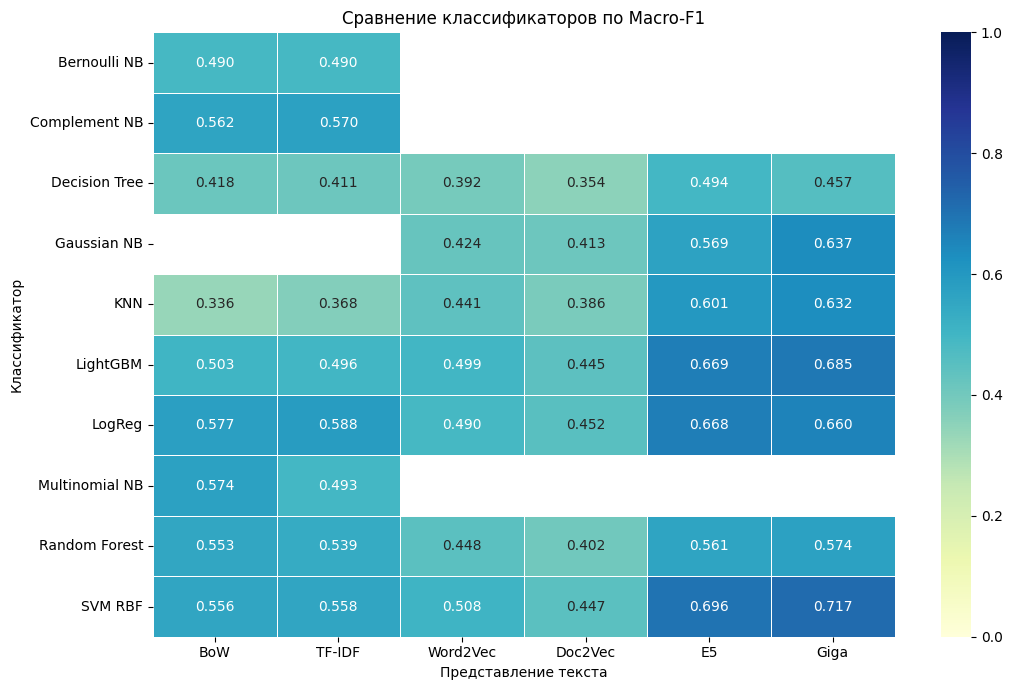

In [28]:
# Подготавливаем таблицу для тепловой карты
heatmap_data = comparison.pivot(
    index="model",
    columns="representation",
    values="macro_f1"
)

# Устанавливаем порядок представлений
heatmap_data = heatmap_data.reindex(
    columns=["BoW", "TF-IDF", "Word2Vec", "Doc2Vec", "E5", "Giga"]
)

# Строим тепловую карту качества классификаторов
plt.figure(figsize=(11, 7))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    linewidths=0.5,
    vmin=0,
    vmax=1
)

plt.title("Сравнение классификаторов по Macro-F1")
plt.xlabel("Представление текста")
plt.ylabel("Классификатор")
plt.tight_layout()
plt.show()


Сравним модели с правилом, которое не читает текст: всегда выдавать самый частый класс обучения. Это базовый уровень, который помогает понять, что дали признаки и обучение.

**5. Оцените постоянный прогноз самого частого класса: найдите этот класс по train и рассчитайте accuracy и macro-F1 на valid.**

> 📚 **Подсказка:** [**DummyClassifier**](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html) со стратегией `most_frequent`.

In [30]:
from sklearn.dummy import DummyClassifier

# Создаём классификатор, предсказывающий самый частый класс
dummy_model = DummyClassifier(strategy="most_frequent")

# Обучаем на исходных обучающих метках
dummy_model.fit(X_bow_train, train["label"])

# Получаем прогнозы для валидационной выборки
dummy_pred = dummy_model.predict(X_bow_valid)

# Вычисляем метрики
dummy_accuracy = accuracy_score(valid["label"], dummy_pred)
dummy_macro_f1 = f1_score(
    valid["label"],
    dummy_pred,
    average="macro",
    zero_division=0
)

print("Самый частый класс:", train["label"].mode()[0])
print(f"Accuracy постоянного прогноза: {dummy_accuracy:.4f}")
print(f"Macro-F1 постоянного прогноза: {dummy_macro_f1:.4f}")

# Сравниваем с лучшей моделью
best_result = comparison.iloc[0]

print("\nЛучшая модель:")
print(best_result["representation"], "+", best_result["model"])
print(f"Macro-F1: {best_result['macro_f1']:.4f}")
print(f"Превышение над постоянным прогнозом: {best_result['macro_f1'] - dummy_macro_f1:.4f}")


Самый частый класс: neutral
Accuracy постоянного прогноза: 0.4833
Macro-F1 постоянного прогноза: 0.2172

Лучшая модель:
Giga + SVM RBF
Macro-F1: 0.7171
Превышение над постоянным прогнозом: 0.4998


**Вопрос:** Улучшили ли эмбеддинги E5 и Giga результат каждого классификатора по сравнению с TF-IDF? Приведите два-три примера из тепловой карты. Как выглядят результаты Word2Vec и Doc2Vec относительно TF-IDF? Насколько лучшие модели превосходят постоянный прогноз?

**Ответ:** По результатам сравнения видно, что использование E5 и Giga в большинстве случаев повысило качество классификации по сравнению с TF-IDF. Однако улучшение наблюдалось не для всех алгоритмов.

Наиболее заметный прирост получен для SVM RBF: при использовании TF-IDF значение macro-F1 составило 0,5582, с E5 оно увеличилось до 0,6962, а с Giga — до 0,7171. Аналогичная ситуация наблюдается у LightGBM: значение выросло с 0,4962 до 0,6694 и 0,6851 соответственно. Для логистической регрессии лучший результат показал E5 (0,6685), немного опередив Giga (0,6598).

При этом дерево решений с E5 показало результат 0,4938, а с Giga — 0,4573, что указывает на зависимость эффективности эмбеддингов от выбранного классификатора.

Word2Vec и Doc2Vec в большинстве случаев уступили TF-IDF. Например, у логистической регрессии macro-F1 составил 0,5882 для TF-IDF, 0,4905 для Word2Vec и 0,4516 для Doc2Vec. Однако у KNN Word2Vec оказался лучше TF-IDF: 0,4410 против 0,3682.

Лучшей комбинацией стала Giga + SVM RBF с macro-F1 = 0,7171 и accuracy = 0,7304. Постоянный прогноз наиболее распространённого класса neutral получил macro-F1 = 0,2172 и accuracy = 0,4833.

Таким образом, лучшая модель превосходит постоянный прогноз на 0,4998 по macro-F1, или примерно на 50 процентных пунктов. Полученные результаты показывают, что использование контекстных эмбеддингов может значительно повысить качество определения тональности, но итоговая эффективность зависит также от выбранного алгоритма классификации.

---

### **1.9. Кросс-валидация и подбор параметров**

> 📚 **Подсказка:** [**Кросс-валидация и подбор гиперпараметров**](https://colab.research.google.com/drive/1xSmltveF3hdM-Hf6tDO88ME7zqQAu0MT#scrollTo=5UlBaXOpxQkL); [**параметры модели в Pipeline**](https://colab.research.google.com/drive/1S_j8HeJEeUU83cjc7cA3Rpkiya-BNiE1#scrollTo=f147b7da).

Оценка на одной валидационной выборке зависит от того, какие тексты в неё попали. Кросс-валидация покажет, насколько меняется результат при нескольких разделениях обучающей части.

**1. Оцените устойчивость одной словарной связки.** Соберите `make_pipeline(CountVectorizer(...), TfidfTransformer(), ComplementNB())` с параметрами словаря из раздела 1.4 и оцените её на `train.text` тремя стратифицированными разбиениями: `StratifiedKFold(3, shuffle=True, random_state=SEED)`, `scoring='f1_macro'`. Векторизатор находится внутри Pipeline, поэтому словарь каждого разбиения строится только по его обучающим текстам. Выведите три оценки, их среднее и стандартное отклонение.

In [31]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

# Создаём конвейер обработки текста и классификации
cv_pipeline = make_pipeline(
    CountVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_features=20000,
        dtype=np.float64
    ),
    TfidfTransformer(),
    ComplementNB(alpha=1)
)

# Три стратифицированных разбиения
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

# Оцениваем качество на каждом разбиении
cv_scores = cross_val_score(
    cv_pipeline,
    train["text"],
    train["label"],
    cv=cv,
    scoring="f1_macro",
    n_jobs=1
)

print("Результаты кросс-валидации:")
for i, score in enumerate(cv_scores, start=1):
    print(f"Разбиение {i}: Macro-F1 = {score:.4f}")

print(f"\nСреднее Macro-F1: {cv_scores.mean():.4f}")
print(f"Стандартное отклонение: {cv_scores.std():.4f}")


Результаты кросс-валидации:
Разбиение 1: Macro-F1 = 0.5555
Разбиение 2: Macro-F1 = 0.5356
Разбиение 3: Macro-F1 = 0.5502

Среднее Macro-F1: 0.5471
Стандартное отклонение: 0.0084


**2. Подберите параметр для двух перспективных связок.** По таблице `comparison` выберите две связки и обоснуйте выбор. Для каждой проверьте три значения одного параметра. Запишите выбор в список `choices` в формате `(представление, модель, параметр, [значение1, значение2, значение3])`; первые два элемента должны совпадать с названиями в `comparison`.

Для моделей внутри Pipeline имя параметра содержит название шага: `svc__C` для SVM, `logisticregression__C` для логистической регрессии, `kneighborsclassifier__n_neighbors` для KNN. Для остальных — просто имя: `num_leaves` (LightGBM), `max_depth` (дерево), `alpha` (Байес). Доступные имена выводит `fitted[(представление, модель)].get_params()`.

<details>
<summary><b>Пример кода</b></summary>

```python
choices = [
    ('TF-IDF', 'Complement NB', 'alpha', [0.1, 1, 3]),
    ('E5', 'SVM RBF', 'svc__C', [1, 3, 10]),
]
```

</details>

In [32]:
# Выбираем две перспективные модели для настройки
choices = [
    ("Giga", "SVM RBF", "svc__C", [1, 3, 10]),
    ("E5", "LogReg", "logisticregression__C", [0.1, 1, 5])
]

In [33]:
tuning, candidates = [], {}  # Результаты подбора и обученные варианты.
for representation, name, parameter, values in choices:  # Перебираем выбранные связки.
    X_train, X_valid, _ = features[representation]  # Используем уже рассчитанные признаки.
    base = fitted[(representation, name)]  # Исходная обученная модель.
    for value in values:  # Меняем один параметр.
        model = base if value == base.get_params()[parameter] else clone(base).set_params(**{parameter: value}).fit(X_train, train.label)  # Повторно не обучаем исходный вариант.
        score = f1_score(valid.label, model.predict(X_valid), average='macro')  # Оцениваем на валидации.
        tuning.append({'representation': representation, 'model': name, 'parameter': parameter, 'value': value, 'macro_f1': score})  # Сохраняем результат.
        candidates[(representation, name, value)] = model  # Сохраняем вариант модели.
tuning_table = pd.DataFrame(tuning).sort_values('macro_f1', ascending=False)  # Лучший вариант первым.
show(tuning_table.round(3))  # Выводим результаты подбора.

,representation,model,parameter,value,macro_f1
0,Giga,SVM RBF,svc__C,1.0,0.725
2,Giga,SVM RBF,svc__C,10.0,0.721
1,Giga,SVM RBF,svc__C,3.0,0.717
3,E5,LogReg,logisticregression__C,0.1,0.670
4,E5,LogReg,logisticregression__C,1.0,0.668
5,E5,LogReg,logisticregression__C,5.0,0.668


**3. Сохраните лучший вариант:** `sentiment_model` — модель из `candidates` для первой строки `tuning_table`, `sentiment_representation` — её представление.

In [34]:
# Выбираем строку с максимальным Macro-F1
best = tuning_table.iloc[0]

# Сохраняем выбранное представление
sentiment_representation = best["representation"]

# Получаем обученную модель из словаря candidates
sentiment_model = candidates[
    (best["representation"], best["model"], best["value"])
]

print("Итоговая модель:", best["model"])
print("Представление текста:", sentiment_representation)
print("Оптимальный параметр:", best["parameter"], "=", best["value"])
print(f"Macro-F1 на валидации: {best['macro_f1']:.4f}")


Итоговая модель: SVM RBF
Представление текста: Giga
Оптимальный параметр: svc__C = 1.0
Macro-F1 на валидации: 0.7245


**Вопрос:** Какие гипотезы поддерживаются полученными результатами, а какие нет? Приведите значения macro-F1 для сравниваемых вариантов. Что изменил подбор параметра и насколько различаются три оценки кросс-валидации?

**Ответ:** Первая гипотеза о преимуществе TF-IDF перед BoW подтвердилась частично. Например, логистическая регрессия с TF-IDF получила macro-F1 = 0,5882, а с BoW — 0,5768. Однако для Multinomial NB результат оказался противоположным: BoW обеспечил 0,5740, а TF-IDF — 0,4932. Следовательно, эффективность представления текста зависит от алгоритма классификации.

Вторая гипотеза о положительном влиянии сбалансированных весов классов пока не получила прямого подтверждения, поскольку отдельное сравнение одного и того же алгоритма с весами и без них не проводилось.

Подбор гиперпараметров позволил улучшить результаты обеих выбранных моделей. Для Giga + SVM RBF изменение C с 3 до 1 повысило macro-F1 примерно с 0,7171 до 0,725. Для E5 + LogReg изменение C с 1 до 0,1 дало небольшой прирост примерно с 0,6685 до 0,670.

При трёхкратной кросс-валидации модели TF-IDF + ComplementNB были получены значения 0,5555, 0,5356 и 0,5502. Среднее составило 0,5471, стандартное отклонение — 0,0084. Разница между максимальным и минимальным значениями равна 0,0199, что свидетельствует об относительно небольшом изменении качества между разбиениями.

---

### **1.10. Итоговая проверка на тесте**

> 📚 **Подсказка:** [**Матрица ошибок**](https://colab.research.google.com/drive/1P5GxyckR2Bb5clpEs2EflKo1JU7D5ULu#scrollTo=4c672369); [**Precision, Recall и F1**](https://colab.research.google.com/drive/1P5GxyckR2Bb5clpEs2EflKo1JU7D5ULu#scrollTo=7122ac70).

Модель и параметры выбраны по валидации. Теперь проверим их на текстах, которые не участвовали в выборе. Отчёт покажет качество каждого класса, матрица ошибок — какие классы путаются, а чтение примеров поможет понять характер ошибок. После этой проверки параметры модели больше не меняем.

**1. Получите `sentiment_prediction` для тестовой матрицы `features[sentiment_representation][2]` и выведите `classification_report`.**

In [35]:
# Выбираем тестовые признаки нужного представления
X_sentiment_test = features[sentiment_representation][2]

# Получаем предсказания выбранной модели
sentiment_prediction = sentiment_model.predict(X_sentiment_test)

# Выводим итоговый отчёт
print("Результаты классификации на тестовой выборке:")
print(
    classification_report(
        test["label"],
        sentiment_prediction,
        labels=labels,
        digits=4,
        zero_division=0
    )
)

print("Итоговый Macro-F1:",
      round(f1_score(test["label"], sentiment_prediction, average="macro"), 4))


Результаты классификации на тестовой выборке:
              precision    recall  f1-score   support

    negative     0.7164    0.7348    0.7255       660
     neutral     0.7816    0.7809    0.7813      1068
    positive     0.7345    0.7101    0.7221       483

    accuracy                         0.7517      2211
   macro avg     0.7442    0.7420    0.7430      2211
weighted avg     0.7519    0.7517    0.7517      2211

Итоговый Macro-F1: 0.743


**2. Постройте матрицу ошибок.**

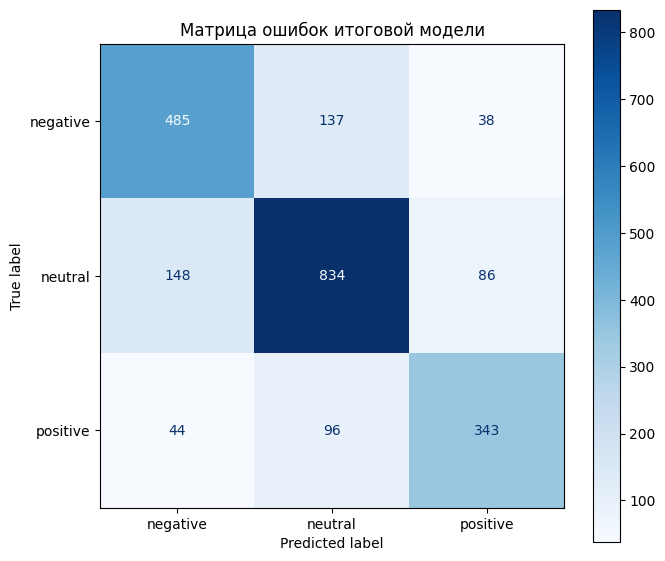

In [36]:
# Строим матрицу ошибок для тестовой выборки
fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay.from_predictions(
    test["label"],
    sentiment_prediction,
    labels=labels,
    display_labels=labels,
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("Матрица ошибок итоговой модели")
plt.tight_layout()
plt.show()


**3. Выведите десять случайных ошибочных прогнозов: текст, разметку и прогноз.**

In [37]:
# Создаём таблицу для анализа предсказаний
errors = test[["text", "label"]].copy()

# Добавляем предсказанный класс
errors["prediction"] = sentiment_prediction

# Оставляем только неправильно классифицированные тексты
errors = errors.loc[
    errors["label"] != errors["prediction"]
].copy()

# Выбираем 10 случайных ошибок
sample_errors = errors.sample(
    n=10,
    random_state=SEED
)

print("Общее количество ошибочных прогнозов:", len(errors))
print("\n10 случайных ошибочных прогнозов:")

show(sample_errors.reset_index(drop=True))


Общее количество ошибочных прогнозов: 549

10 случайных ошибочных прогнозов:


,text,label,prediction
0,@yourfinalsin @acid_beer О нет они нашли меня *скрывается в лесу*,neutral,negative
1,"Громкий вброс Соловьёва, опровержение со стороны КПРФ https://t.co/hbLWOHvoP2 #левые #лейбералы",negative,neutral
2,@_bakana_ ты угадал,positive,neutral
3,"накипело уже, я не кайли дженнер чтобы оплачивать себе дополнительные гигабайты, но я все равно их покупаю потому что по-другому никак.....",negative,neutral
4,@neurasthenic_ Я смотрела в какой-то озвучке и там было:\r\n-я б женился на такой\r\n-мне ещё рано замуж\r\nПЛАЧУ,negative,positive
5,"Шуточки про 14 и 21 балл Феликса и Бени лучшее, что мог дать этот мелфест",positive,neutral
6,"@lIl__muna__ @kpop_asiangirl хех, я просто объяснил матушке, что использую маты для придания большей эмоциональной окраски своей речи.",neutral,positive
7,"@lenywitz ОПАСНЫЙ, но только немножко",negative,neutral
8,@biiinnni_ @changkyun_uf Не дышите,neutral,negative
9,@doramnoefile я сказала чт опросто долго писала лола там реально [скрыто] какойе длинное,neutral,negative


**Вопрос:** Выберите две показанные ошибки. Для каждой укажите разметку, прогноз и слова, которые могли запутать модель. Есть ли в этих текстах сарказм, отрицание или недостаток контекста?

**Ответ:** **Пример 1.** Сообщение: «накипело уже, я не кайли дженнер чтобы оплачивать себе дополнительные гигабайты, но я все равно их покупаю потому что по-другому никак...»

- Исходная разметка: `negative`.
- Прогноз модели: `neutral`.

В сообщении выражено недовольство необходимостью дополнительных расходов. На отрицательную тональность указывают выражения «накипело уже», «не кайли дженнер» и «по-другому никак». При этом текст содержит описание обычной ситуации с покупкой гигабайтов, из-за чего модель могла воспринять его как нейтральное сообщение. Здесь также присутствует ирония, связанная с упоминанием обеспеченного человека.

**Пример 2.** Сообщение: «ОПАСНЫЙ, но только немножко».

- Исходная разметка: `negative`.
- Прогноз модели: `neutral`.

Слово «опасный» может выражать отрицательную оценку, однако продолжение «но только немножко» смягчает её и делает смысл неоднозначным. Без дополнительного контекста трудно определить, является ли высказывание серьёзным предупреждением, шуткой или иронией.

В обоих случаях ошибка может быть связана с особенностями разговорной речи. Для правильной интерпретации недостаточно распознавать отдельные слова — необходимо также учитывать контекст, отрицания и эмоциональные оттенки высказывания.

---

### **1.11. Выводы по части 1**

Опишите, какое представление текста и какой классификатор вы выбрали и почему. Приведите macro-F1 на валидации и тесте и укажите, какие классы модель путает чаще всего.

**Вывод:** По результатам сравнения моделей для классификации тональности была выбрана комбинация **Giga + SVM RBF**, показавшая наилучшее качество. Эмбеддинги Giga позволяют учитывать контекст и смысл текста, а SVM эффективно разделяет сообщения по классам.

После подбора параметра C = 1 модель достигла **macro-F1 = 0,7245 на валидационной выборке и 0,7430 на тестовой**.

Анализ матрицы ошибок показал, что чаще всего модель путает нейтральные и отрицательные сообщения. Основные сложности возникают при обработке неоднозначных формулировок, иронии и текстов с недостаточным контекстом.

Таким образом, выбранная модель показала достаточно высокое качество классификации и может использоваться для дальнейшего анализа тональности отзывов.

---

## **Часть 2. Звёзды по тексту отзыва**

**Задача:** по тексту отзыва предсказать оценку автора от 1 до 5. Каждая оценка — отдельный класс.

**Датасет:** [Geo Reviews Dataset 2023](https://github.com/yandex/geo-reviews-dataset-2023) содержит 500 000 отзывов об организациях с текстом, названием, адресом, рубриками и оценкой. Описание и лицензия — в официальном репозитории; загрузим [опубликованную копию](https://huggingface.co/datasets/d0rj/geo-reviews-dataset-2023) в формате Parquet.

Здесь звёзды известны и служат целевой переменной для обучения. При применении будем сравнивать прогноз по тексту с оценкой автора и отбирать заметные расхождения для чтения. Обученная модель станет вторым «читателем», дополняющим модель тональности.

### **2.1. Загрузка и очистка**

In [38]:
dataset_url = 'https://huggingface.co/datasets/d0rj/geo-reviews-dataset-2023/resolve/02366bc66bd43aa69e707747487ec8f3c22cac84/data/train-00000-of-00001-49261e4e5a35a5a0.parquet'  # Закреплённая версия набора.
local_parquet = Path('geo_reviews.parquet')  # Локальная копия для повторных запусков.
if not local_parquet.exists():  # Скачиваем один раз.
    pd.read_parquet(dataset_url).to_parquet(local_parquet)  # Сохраняем таблицу на диск среды.
rating_source = pd.read_parquet(local_parquet)  # Читаем отзывы.
show(rating_source.head(3))  # Смотрим столбцы.

,address,name_ru,rating,rubrics,text
0,"Екатеринбург, ул. Московская / ул. Волгоградская / ул. Печатников",Московский квартал,3,Жилой комплекс,"Московский квартал 2.\nШумно : летом по ночам дикие гонки. Грязно : кругом стройки, невозможно открыть окна (16 этаж! ), вечно по району летает мусор. Детские площадки убогие, на большой площади однотипные конструкции. Очень дорогая коммуналка. Часто срабатывает пожарная сигнализация. Жильцы уже не реагируют. В это время, обычно около часа, не работают лифты. Из плюсов - отличная планировка квартир ( Московская 194 ), на мой взгляд. Ремонт от застройщика на 3-. Окна вообще жуть - вместо вентиляции. По соотношению цена/качество - 3."
1,"Московская область, Электросталь, проспект Ленина, 29",Продукты Ермолино,5,"Магазин продуктов;Продукты глубокой заморозки;Магазин мяса, колбас","Замечательная сеть магазинов в общем, хороший ассортимент, цены приемлемые, а главное качество на высоте!!! Спасибо тем, кто открыл сеть этих магазинчиков!!!!"
2,"Краснодар, Прикубанский внутригородской округ, микрорайон имени Петра Метальникова, улица Петра Метальникова, 26",LimeFit,1,Фитнес-клуб,"Не знаю смутят ли кого-то данные правила, но я была удивлена: \n1. Хочешь что бы твой шкаф замыкался - купи замочек\n2. Ты должен предоставить свой отпечаток пальца (полнейшая дичь) \n3. Ставят подпись на договоре с клиентом по доверенности , графу с номером доверенности оставляют пустой , а на вопрос о номере доверенности говорят номер «2»\nВы серьезно? Номер 2? \nПредоставить доверенность не могут, но говорят что у них в клубе «свои» доверенности, типа особенные какие-то \nЦирк."


**Выведите число отзывов, распределение оценок и число пропусков в каждом столбце.**

Общее количество отзывов: 500000
Количество столбцов: 5

Пропуски по столбцам:
address      0
name_ru    970
rating       0
rubrics      0
text         0

Количество отзывов по оценкам:
rating
0       200
1     34351
2     12088
3     21686
4     41160
5    390515

Доля каждой оценки (%):
rating
0     0.04
1     6.87
2     2.42
3     4.34
4     8.23
5    78.10


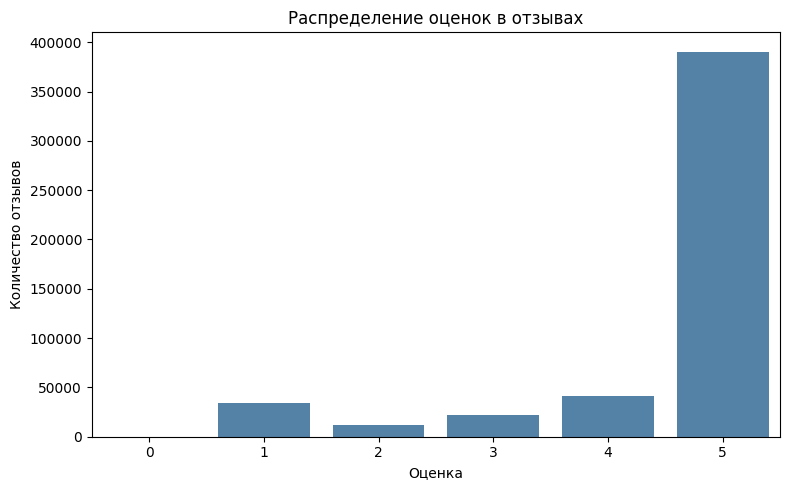

In [39]:
# Определяем размер исходного набора данных
print("Общее количество отзывов:", len(rating_source))
print("Количество столбцов:", rating_source.shape[1])

# Проверяем пропущенные значения
print("\nПропуски по столбцам:")
missing_values = rating_source.isna().sum()
print(missing_values.to_string())

# Анализируем распределение оценок
print("\nКоличество отзывов по оценкам:")
rating_counts = rating_source["rating"].value_counts().sort_index()
print(rating_counts.to_string())

# Рассчитываем процент каждой оценки
print("\nДоля каждой оценки (%):")
rating_percent = (
    rating_source["rating"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)
print(rating_percent.to_string())

# Визуализируем распределение
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=rating_source,
    x="rating",
    order=sorted(rating_source["rating"].dropna().unique()),
    color="steelblue"
)

plt.title("Распределение оценок в отзывах")
plt.xlabel("Оценка")
plt.ylabel("Количество отзывов")

plt.tight_layout()
plt.show()


Готовая ячейка ниже оставляет оценки 1–5, удаляет пустые и повторные тексты и формирует ключ организации из нормированных названия и адреса. Название и адрес не входят в признаки модели: они нужны, чтобы отзывы одной организации не попали одновременно в обучение и тест.

In [40]:
rating_df = rating_source.copy()  # Рабочая копия.
rating_df['text_key'] = text_key(rating_df.text)  # Ключ текста из части 1.
conflict = rating_df.groupby('text_key').rating.transform('nunique').gt(1)  # Одинаковые тексты с разными оценками.
keep = rating_df.rating.isin([1, 2, 3, 4, 5]) & rating_df.name_ru.notna() & rating_df.address.notna() & rating_df.text_key.ne('') & ~conflict  # Пригодные записи.
rating_df = rating_df.loc[keep].drop_duplicates('text_key').reset_index(drop=True)  # Один экземпляр каждого текста.
rating_df['organization_key'] = text_key(rating_df.name_ru) + ' | ' + text_key(rating_df.address)  # Приближённый ключ организации.
print('Пригодных отзывов:', len(rating_df))  # Объём после очистки.

Пригодных отзывов: 498679


**Вопрос:** Какая доля отзывов имеет пять звёзд? Почему записи с оценкой 0 исключаем из этой задачи?

**Ответ:** В исходном наборе данных 390 515 отзывов имеют оценку 5 звёзд, что составляет 78,10% от общего количества. Такое распределение свидетельствует о значительном преобладании положительных оценок.

Записи с оценкой 0 исключаются, поскольку в данной задаче модель должна предсказывать одну из пяти оценок — от 1 до 5. Нулевая оценка не входит в заданную шкалу и не рассматривается как отдельный целевой класс. Её включение нарушило бы постановку задачи классификации.

---

### **2.2. Выборка и разделение по организациям**

Для сравнения моделей возьмём 10 000 отзывов, сохранив доли оценок. Все представления и классификаторы используют одни и те же строки.

**1. Получите `rating_sample` вызовом `train_test_split(rating_df, train_size=10000, stratify=rating_df.rating, random_state=SEED)` (вторую часть результата не используем) и сравните доли оценок в `rating_df` и `rating_sample`.**

In [41]:
# Отбираем 10 000 отзывов с сохранением долей оценок
rating_sample, _ = train_test_split(
    rating_df,
    train_size=10000,
    stratify=rating_df["rating"],
    random_state=SEED
)

rating_sample = rating_sample.reset_index(drop=True)

# Сравниваем распределение оценок
distribution = pd.DataFrame({
    "Исходные данные (%)": rating_df["rating"].value_counts(normalize=True) * 100,
    "Выборка (%)": rating_sample["rating"].value_counts(normalize=True) * 100
}).sort_index()

print("Количество отобранных отзывов:", len(rating_sample))
print("\nРаспределение оценок:")
display(distribution.round(2))


Количество отобранных отзывов: 10000

Распределение оценок:


,Исходные данные (%),Выборка (%)
rating,,
1,6.88,6.88
2,2.42,2.42
3,4.34,4.34
4,8.24,8.24
5,78.12,78.12


> 📚 **Подсказка:** [**GroupShuffleSplit**](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html) помещает все строки одной группы в одну часть.

Отзывы одной организации похожи: в них повторяются названия блюд, имена сотрудников, одни и те же проблемы. Если такие отзывы попадут и в обучение, и в тест, модель получит подсказку, которой не будет у новой организации. Поэтому делим не отзывы, а организации: 20% — тест, четверть оставшихся — валидация.

In [42]:
from sklearn.model_selection import GroupShuffleSplit  # Разделение целыми группами.
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)  # Отделяем тест.
remaining, test_indices = next(splitter.split(rating_sample, groups=rating_sample.organization_key))  # Индексы строк.
development_ratings = rating_sample.iloc[remaining]  # Обучение и валидация.
splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED + 1)  # Отделяем валидацию.
train_indices, valid_indices = next(splitter.split(development_ratings, groups=development_ratings.organization_key))  # Индексы строк.
rating_train = development_ratings.iloc[train_indices].reset_index(drop=True)  # Обучение.
rating_valid = development_ratings.iloc[valid_indices].reset_index(drop=True)  # Валидация.
rating_test = rating_sample.iloc[test_indices].reset_index(drop=True)  # Тест.
print('Размеры:', len(rating_train), len(rating_valid), len(rating_test))  # Доли задавались для организаций, а не отзывов.

Размеры: 5997 1997 2006


**2. Проверьте, что ни одна пара частей не имеет общих организаций (`organization_key`) и общих текстов (`text_key`).**

In [43]:
# Проверяем отсутствие пересечений
parts = {
    "Train": rating_train,
    "Valid": rating_valid,
    "Test": rating_test
}

from itertools import combinations

for (name1, df1), (name2, df2) in combinations(parts.items(), 2):

    common_orgs = (
        set(df1["organization_key"])
        & set(df2["organization_key"])
    )

    common_texts = (
        set(df1["text_key"])
        & set(df2["text_key"])
    )

    print(f"{name1} / {name2}")
    print("Общих организаций:", len(common_orgs))
    print("Общих текстов:", len(common_texts))
    print()


Train / Valid
Общих организаций: 0
Общих текстов: 0

Train / Test
Общих организаций: 0
Общих текстов: 0

Valid / Test
Общих организаций: 0
Общих текстов: 0



---

### **2.3. Признаки отзывов**

Сравним словарные признаки с лучшим энкодером части 1. Энкодер используем повторно, а классификаторы обучаем заново: у них новая целевая переменная.

**1. Создайте `rating_bow = CountVectorizer(ngram_range=(1, 2), min_df=3, max_features=30000, dtype=np.float64)` и `rating_tfidf = TfidfTransformer()`. Получите матрицы `R_bow_train`, `R_bow_valid`, `R_bow_test` и `R_tfidf_train`, `R_tfidf_valid`, `R_tfidf_test`, обучая словарь и веса только на `rating_train`.**

In [44]:
# Создаём словарь из отдельных слов и биграмм
rating_bow = CountVectorizer(
    ngram_range=(1, 2),
    min_df=3,
    max_features=30000,
    dtype=np.float64
)

# Обучаем словарь только на тренировочных отзывах
R_bow_train = rating_bow.fit_transform(rating_train["text"])

# Преобразуем валидационные и тестовые отзывы
R_bow_valid = rating_bow.transform(rating_valid["text"])
R_bow_test = rating_bow.transform(rating_test["text"])

# Создаём TF-IDF
rating_tfidf = TfidfTransformer()

R_tfidf_train = rating_tfidf.fit_transform(R_bow_train)
R_tfidf_valid = rating_tfidf.transform(R_bow_valid)
R_tfidf_test = rating_tfidf.transform(R_bow_test)

print("Размерности матриц BoW:")
print("Train:", R_bow_train.shape)
print("Valid:", R_bow_valid.shape)
print("Test:", R_bow_test.shape)

print("\nРазмерности матриц TF-IDF:")
print("Train:", R_tfidf_train.shape)
print("Valid:", R_tfidf_valid.shape)
print("Test:", R_tfidf_test.shape)

print("\nРазмер словаря:", len(rating_bow.vocabulary_))


Размерности матриц BoW:
Train: (5997, 17631)
Valid: (1997, 17631)
Test: (2006, 17631)

Размерности матриц TF-IDF:
Train: (5997, 17631)
Valid: (1997, 17631)
Test: (2006, 17631)

Размер словаря: 17631


Повторно используем один из готовых энкодеров: его веса не зависят от целевой переменной. Выбор по части 1 — отправная точка; преимущество на отзывах проверим отдельным сравнением со словарными признаками.

**2. По таблице `comparison` выберите среди `'E5'` и `'Giga'` представление с наибольшим macro-F1 и сохраните его название в `modern_best`.**

In [45]:
# Сравниваем лучшие результаты E5 и Giga
modern_scores = (
    comparison[comparison["representation"].isin(["E5", "Giga"])]
    .groupby("representation")["macro_f1"]
    .max()
    .sort_values(ascending=False)
)

modern_best = modern_scores.index[0]

print("Лучшие результаты нейросетевых представлений:")
print(modern_scores.round(4))

print("\nВыбранное представление:", modern_best)


Лучшие результаты нейросетевых представлений:
representation
Giga    0.7171
E5      0.6962
Name: macro_f1, dtype: float64

Выбранное представление: Giga


**Длинные отзывы.** Энкодер принимает ограниченное число токенов — частей слов и знаков. Отзывы бывают длиннее этого предела, а скрытое обрезание потеряло бы конец текста, где автор часто подводит итог. Готовая функция `review_vectors` делит длинный отзыв на фрагменты, получает их векторы и объединяет с весами по длине; короткий отзыв проходит одним фрагментом. Функция `text_features` получает признаки новых текстов тем же способом, что при обучении модели, — она понадобится в части 3. [Ограничение длины входа](https://www.sbert.net/examples/sentence_transformer/applications/computing-embeddings/README.html#input-sequence-length).

In [46]:
# Готовые функции признаков для новых текстов
def review_vectors(texts, encoder, prompt=''):  # Векторы отзывов любой длины.
    tokenized = encoder.tokenizer(list(texts), add_special_tokens=False)['input_ids']  # Токены каждого текста.
    pieces, owners, weights = [], [], []  # Фрагменты, номер исходного отзыва и вес.
    capacity = encoder.max_seq_length - 32  # Место для префикса и служебных токенов.
    for i, ids in enumerate(tokenized):  # Перебираем отзывы.
        for start in range(0, max(1, len(ids)), capacity):  # Делим на фрагменты, сохраняя конец текста.
            chunk = ids[start:start + capacity]  # Очередной фрагмент.
            pieces.append(encoder.tokenizer.decode(chunk))  # Текст фрагмента.
            owners.append(i)  # Номер исходного отзыва.
            weights.append(max(1, len(chunk)))  # Вес по длине.
    vectors = encoder.encode(pieces, prompt=prompt, batch_size=16, normalize_embeddings=True, show_progress_bar=True)  # Векторы фрагментов.
    matrix = np.zeros((len(texts), vectors.shape[1]), dtype=np.float32)  # Строка на отзыв.
    np.add.at(matrix, owners, vectors * np.asarray(weights, dtype=np.float32)[:, None])  # Складываем фрагменты с весами.
    return normalize(matrix)  # Единичная длина, как у encode.

_feature_cache = {}  # Признаки уже обработанных наборов текстов.
def text_features(texts, representation, part):  # Признаки текстов для модели части 1 или части 2.
    texts = [str(text) for text in texts]  # Список строк.
    encoders = {'E5': (e5, 'query: '), 'Giga': (giga, '')}  # Энкодеры и их префиксы.
    key = (representation if representation in encoders else (representation, part), hash(tuple(texts)))  # Энкодер одинаков в обеих частях.
    if key not in _feature_cache:  # Считаем признаки один раз.
        if representation in encoders:  # Нейросетевой энкодер.
            _feature_cache[key] = review_vectors(texts, *encoders[representation])  # Длинные тексты по фрагментам.
        elif representation in ('BoW', 'TF-IDF'):  # Словарные признаки.
            counts = (bow if part == 1 else rating_bow).transform(texts)  # Словарь нужной части.
            _feature_cache[key] = counts if representation == 'BoW' else (tfidf if part == 1 else rating_tfidf).transform(counts)  # Веса нужной части.
        else:  # Word2Vec и Doc2Vec обучены в части 1.
            _feature_cache[key] = word_vectors(texts) if representation == 'Word2Vec' else doc_vectors(texts)  # Те же функции.
    return _feature_cache[key]  # Матрица признаков.

**3. Получите векторы всех 10 000 отзывов одним вызовом `text_features(rating_texts, modern_best, part=2)`, где `rating_texts` — тексты train, valid и test подряд. Разделите матрицу на `R_modern_train`, `R_modern_valid`, `R_modern_test` и измерьте время расчёта.**

In [47]:
# Объединяем отзывы в установленном порядке
rating_texts = (
    rating_train["text"].tolist()
    + rating_valid["text"].tolist()
    + rating_test["text"].tolist()
)

# Запоминаем границы выборок
rating_split_positions = [
    len(rating_train),
    len(rating_train) + len(rating_valid)
]

# Измеряем время расчёта эмбеддингов
start = perf_counter()

R_modern = text_features(
    rating_texts,
    modern_best,
    part=2
)

embedding_seconds = perf_counter() - start

# Разделяем матрицу на три выборки
R_modern_train, R_modern_valid, R_modern_test = np.split(
    R_modern,
    rating_split_positions
)

print("Нейросетевое представление:", modern_best)
print("Размерность общей матрицы:", R_modern.shape)

print("\nРазмерности выборок:")
print("Train:", R_modern_train.shape)
print("Valid:", R_modern_valid.shape)
print("Test:", R_modern_test.shape)

print(f"\nВремя расчёта эмбеддингов: {embedding_seconds:.2f} сек.")

print("\nПроверка корректности:")
print("Есть NaN:", np.isnan(R_modern).any())
print("Есть бесконечные значения:", np.isinf(R_modern).any())


Batches:   0%|          | 0/625 [00:00<?, ?it/s]

Нейросетевое представление: Giga
Размерность общей матрицы: (10000, 1024)

Размерности выборок:
Train: (5997, 1024)
Valid: (1997, 1024)
Test: (2006, 1024)

Время расчёта эмбеддингов: 227.84 сек.

Проверка корректности:
Есть NaN: False
Есть бесконечные значения: False


---

### **2.4. Сравнение классификаторов**

В части 1 мы выбрали алгоритмы для тональности. Теперь обучим выбранные алгоритмы предсказывать пять классов звёзд. `clone` создаёт необученную копию с теми же настройками; обученный классификатор тональности сохраняем для его собственной задачи.

**1. Создайте словарь `rating_estimators` из трёх классификаторов:**

- `'SVM RBF'`: `SVC(C=1, kernel='rbf', class_weight='balanced', cache_size=512)`;
- `'LogReg'`: копия `clone(base_models['LogReg'])`;
- ещё один классификатор из `base_models` (KNN, Decision Tree, Random Forest или LightGBM), который вы выбираете по качеству и времени обучения в части 1. Ключ должен совпадать с названием в `base_models`.

In [48]:
# Выбираем три алгоритма для прогнозирования оценок
rating_estimators = {
    "SVM RBF": SVC(
        C=1,
        kernel="rbf",
        class_weight="balanced",
        cache_size=512
    ),

    "LogReg": clone(base_models["LogReg"]),

    "LightGBM": clone(base_models["LightGBM"])
}

print("Выбранные классификаторы:")
for name in rating_estimators:
    print("-", name)

print("\nВсего классификаторов:", len(rating_estimators))


Выбранные классификаторы:
- SVM RBF
- LogReg
- LightGBM

Всего классификаторов: 3


Готовый цикл обучает каждую связку на `rating_train` и оценивает на `rating_valid`. Для словарных признаков добавлены Multinomial и Complement NB. **MAE** — средняя абсолютная ошибка в звёздах: прогноз 2 при оценке 5 даёт ошибку 3.

In [49]:
from sklearn.metrics import mean_absolute_error  # Ошибка в звёздах.
rating_features = {'BoW': (R_bow_train, R_bow_valid, R_bow_test), 'TF-IDF': (R_tfidf_train, R_tfidf_valid, R_tfidf_test), modern_best: (R_modern_train, R_modern_valid, R_modern_test)}  # Готовые признаки.
rating_rows, rating_models = [], {}  # Метрики и обученные модели.
for representation, (X_train, X_valid, _) in rating_features.items():  # Перебираем представления.
    models = {**rating_estimators, **({'Multinomial NB': MultinomialNB(), 'Complement NB': ComplementNB()} if sparse.issparse(X_train) else {})}  # Байес только для частот.
    for name, estimator in models.items():  # Перебираем классификаторы.
        model = clone(estimator)  # Новая копия.
        if name in scaled_models:  # Масштабирование, как в части 1.
            model = make_pipeline(Normalizer() if sparse.issparse(X_train) else StandardScaler(), model)  # Учим преобразование по train.
        start = perf_counter()  # Начало обучения.
        model.fit(X_train, rating_train.rating)  # Обучаем на звёздах.
        fit_seconds = perf_counter() - start  # Длительность обучения.
        prediction = model.predict(X_valid)  # Прогноз валидации.
        rating_rows.append({'representation': representation, 'model': name, 'macro_f1': f1_score(rating_valid.rating, prediction, average='macro'), 'accuracy': accuracy_score(rating_valid.rating, prediction), 'mae_stars': mean_absolute_error(rating_valid.rating, prediction), 'fit_seconds': fit_seconds})  # Метрики.
        rating_models[(representation, name)] = model  # Сохраняем модель.
        print(representation, name, round(rating_rows[-1]['macro_f1'], 3))  # Ход сравнения.
rating_comparison = pd.DataFrame(rating_rows).sort_values('macro_f1', ascending=False)  # Таблица сравнения.
show(rating_comparison.round(3))  # Выводим результаты.

BoW SVM RBF 0.404
BoW LogReg 0.443
BoW LightGBM 0.436
BoW Multinomial NB 0.396
BoW Complement NB 0.384
TF-IDF SVM RBF 0.376
TF-IDF LogReg 0.469
TF-IDF LightGBM 0.434
TF-IDF Multinomial NB 0.175
TF-IDF Complement NB 0.346
Giga SVM RBF 0.52
Giga LogReg 0.465
Giga LightGBM 0.471


,representation,model,macro_f1,accuracy,mae_stars,fit_seconds
10,Giga,SVM RBF,0.520,0.842,0.213,15.503
12,Giga,LightGBM,0.471,0.849,0.222,100.210
6,TF-IDF,LogReg,0.469,0.780,0.389,2.418
11,Giga,LogReg,0.465,0.800,0.290,6.109
1,BoW,LogReg,0.443,0.739,0.475,2.279
2,BoW,LightGBM,0.436,0.764,0.411,4.105
7,TF-IDF,LightGBM,0.434,0.787,0.380,12.671
0,BoW,SVM RBF,0.404,0.793,0.391,20.050
3,BoW,Multinomial NB,0.396,0.820,0.309,0.005
4,BoW,Complement NB,0.384,0.807,0.373,0.004


**2. Рассчитайте accuracy, macro-F1 и MAE постоянного прогноза пяти звёзд на `rating_valid`.**

In [50]:
# Формируем постоянный прогноз пяти звёзд
constant_prediction = np.full(
    len(rating_valid),
    5
)

# Рассчитываем метрики
constant_accuracy = accuracy_score(
    rating_valid["rating"],
    constant_prediction
)

constant_f1 = f1_score(
    rating_valid["rating"],
    constant_prediction,
    average="macro",
    zero_division=0
)

constant_mae = mean_absolute_error(
    rating_valid["rating"],
    constant_prediction
)

print("Постоянный прогноз: 5 звёзд")
print(f"Accuracy: {constant_accuracy:.4f}")
print(f"Macro-F1: {constant_f1:.4f}")
print(f"MAE: {constant_mae:.4f}")

# Сравниваем с лучшим классификатором
best_rating = rating_comparison.iloc[0]

print("\nЛучшая обученная модель:")
print(best_rating["representation"], "+", best_rating["model"])
print(f"Macro-F1: {best_rating['macro_f1']:.4f}")
print(f"Accuracy: {best_rating['accuracy']:.4f}")
print(f"MAE: {best_rating['mae_stars']:.4f}")


Постоянный прогноз: 5 звёзд
Accuracy: 0.7792
Macro-F1: 0.1752
MAE: 0.5343

Лучшая обученная модель:
Giga + SVM RBF
Macro-F1: 0.5203
Accuracy: 0.8418
MAE: 0.2133


**Вопрос:** Почему постоянный прогноз получает высокую accuracy? Какая метрика лучше показывает, распознаёт ли модель низкие оценки? Подтвердилось ли на отзывах преимущество эмбеддингов?

**Ответ:** Постоянный прогноз пяти звёзд показывает высокую accuracy (0,7792), поскольку большинство отзывов имеют именно такую оценку. Однако эта модель совершенно не распознаёт остальные классы.

Для оценки качества при таком дисбалансе лучше использовать macro-F1, поскольку она учитывает результаты каждого класса, включая редкие низкие оценки. У постоянного прогноза macro-F1 составляет всего 0,1752, а у лучшей обученной модели — 0,5203.

Преимущество нейросетевых эмбеддингов подтвердилось. Лучший результат показала комбинация Giga + SVM RBF с accuracy = 0,8418 и MAE = 0,2133. Это свидетельствует о том, что учёт смыслового содержания отзывов помогает точнее определять оценки по сравнению со словарными методами и постоянным прогнозом.

---

### **2.5. Подбор параметров и итоговая проверка**

**1. Выберите две перспективные связки из `rating_comparison` и запишите `rating_choices` в том же формате, что `choices` в части 1.** Для SVM сравните, например, `svc__C` = 0.3, 1, 3; для логистической регрессии — `logisticregression__C` = 0.1, 1, 10; для LightGBM — `num_leaves` = 15, 31, 63.

In [51]:
# Выбираем две перспективные комбинации
rating_choices = [
    ("Giga", "SVM RBF", "svc__C", [0.3, 1, 3]),
    ("TF-IDF", "LogReg", "logisticregression__C", [0.1, 1, 10])
]

print("Выбранные комбинации для настройки:")
for representation, model, parameter, values in rating_choices:
    print(f"{representation} + {model}")
    print(f"Параметр: {parameter}")
    print(f"Проверяемые значения: {values}\n")


Выбранные комбинации для настройки:
Giga + SVM RBF
Параметр: svc__C
Проверяемые значения: [0.3, 1, 3]

TF-IDF + LogReg
Параметр: logisticregression__C
Проверяемые значения: [0.1, 1, 10]



In [52]:
rating_tuning, rating_candidates = [], {}  # Результаты подбора.
for representation, name, parameter, values in rating_choices:  # Перебираем связки.
    X_train, X_valid, _ = rating_features[representation]  # Те же признаки.
    base = rating_models[(representation, name)]  # Исходная модель.
    for value in values:  # Меняем один параметр.
        model = base if value == base.get_params()[parameter] else clone(base).set_params(**{parameter: value}).fit(X_train, rating_train.rating)  # Исходный вариант не переобучаем.
        rating_tuning.append({'representation': representation, 'model': name, 'parameter': parameter, 'value': value, 'macro_f1': f1_score(rating_valid.rating, model.predict(X_valid), average='macro')})  # Оценка на валидации.
        rating_candidates[(representation, name, value)] = model  # Вариант модели.
rating_tuning_table = pd.DataFrame(rating_tuning).sort_values('macro_f1', ascending=False)  # Лучший первым.
show(rating_tuning_table.round(3))  # Результаты подбора.

,representation,model,parameter,value,macro_f1
0,Giga,SVM RBF,svc__C,0.3,0.524
1,Giga,SVM RBF,svc__C,1.0,0.520
2,Giga,SVM RBF,svc__C,3.0,0.506
5,TF-IDF,LogReg,logisticregression__C,10.0,0.476
4,TF-IDF,LogReg,logisticregression__C,1.0,0.469
3,TF-IDF,LogReg,logisticregression__C,0.1,0.448


**2. Сохраните лучший вариант в `rating_model` и его представление в `rating_representation`. Получите `rating_prediction` на тесте и выведите `classification_report`, MAE и долю ошибок не менее чем на две звезды.**

In [53]:
# Выбираем лучший вариант по Macro-F1
best_rating = rating_tuning_table.iloc[0]

rating_representation = best_rating["representation"]

rating_model = rating_candidates[
    (
        best_rating["representation"],
        best_rating["model"],
        best_rating["value"]
    )
]

print("Выбранная модель:", best_rating["model"])
print("Представление:", rating_representation)
print("Оптимальное C:", best_rating["value"])

# Получаем признаки тестовой выборки
X_rating_test = rating_features[rating_representation][2]

# Прогнозируем оценки от 1 до 5
rating_prediction = rating_model.predict(X_rating_test)

# Отчёт по каждому классу
print("\nРезультаты тестирования:")
print(
    classification_report(
        rating_test["rating"],
        rating_prediction,
        labels=[1, 2, 3, 4, 5],
        digits=4,
        zero_division=0
    )
)

# Дополнительные метрики
rating_mae = mean_absolute_error(
    rating_test["rating"],
    rating_prediction
)

rating_macro_f1 = f1_score(
    rating_test["rating"],
    rating_prediction,
    average="macro"
)

# Ошибки на две звезды и более
large_errors = (
    np.abs(
        rating_test["rating"].to_numpy() - rating_prediction
    ) >= 2
).mean()

print(f"Итоговый Macro-F1: {rating_macro_f1:.4f}")
print(f"MAE: {rating_mae:.4f}")
print(f"Доля ошибок >= 2 звёзд: {large_errors:.2%}")


Выбранная модель: SVM RBF
Представление: Giga
Оптимальное C: 0.3

Результаты тестирования:
              precision    recall  f1-score   support

           1     0.6914    0.8582    0.7658       141
           2     0.3000    0.0625    0.1034        48
           3     0.3868    0.4362    0.4100        94
           4     0.3735    0.7118    0.4899       170
           5     0.9777    0.8757    0.9239      1553

    accuracy                         0.8205      2006
   macro avg     0.5459    0.5889    0.5386      2006
weighted avg     0.8625    0.8205    0.8323      2006

Итоговый Macro-F1: 0.5386
MAE: 0.2183
Доля ошибок >= 2 звёзд: 3.14%


**3. Постройте матрицу ошибок для пяти оценок.**

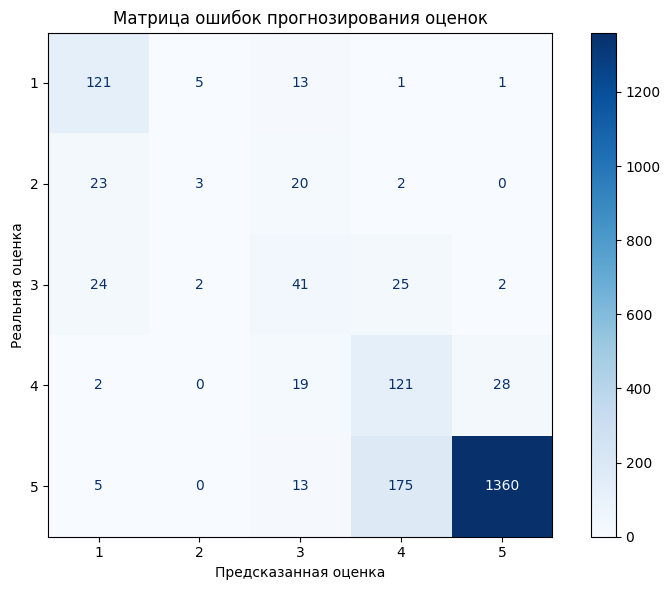

In [54]:
# Строим матрицу ошибок по пяти оценкам
fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    rating_test["rating"],
    rating_prediction,
    labels=[1, 2, 3, 4, 5],
    display_labels=[1, 2, 3, 4, 5],
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("Матрица ошибок прогнозирования оценок")
plt.xlabel("Предсказанная оценка")
plt.ylabel("Реальная оценка")
plt.tight_layout()
plt.show()


**Вопрос:** Какие оценки модель распознаёт хуже всего и с какими соседними оценками путает? Почему расхождение прогноза с оценкой не доказывает, что ошибся автор?

**Ответ:** Хуже всего модель распознаёт оценки 2 и 3 звезды. Для двух звёзд F1 составил всего 0,1034, для трёх — 0,4100. Отзывы с оценкой 2 модель чаще относит к 1 или 3 звёздам, а трёхзвёздочные — к 1 или 4. Также наблюдается путаница между оценками 4 и 5.

Лучше всего определяются крайние оценки: 1 и 5 звёзд, поскольку они чаще сопровождаются более выраженным отношением автора.

При этом несовпадение прогноза с оценкой пользователя не обязательно означает ошибку автора. Оценка может зависеть от личных ожиданий, а текст не всегда отражает все причины её выставления. Кроме того, сама модель может неправильно интерпретировать отзыв, поэтому расхождения требуют дополнительного анализа.

---

### **2.6. Два читателя: ансамбль согласия**

Теперь у нас есть два «читателя» текста. Один определяет тональность, другой предсказывает звёзды. Попробуем отбирать отзывы, в которых оба прогноза расходятся с оценкой автора в одну сторону. Это **правило согласия двух моделей**: его пользу проверим чтением в части 3.

| Столбец | Правило |
|---|---|
| `star_difference` | `predicted_rating − rating`: прогноз звёзд минус оценка автора |
| `candidate` | `abs(star_difference) ≥ 2`: модель звёзд расходится с автором минимум на две звезды |
| `both` | `star_difference ≤ −2` и тональность `negative` **или** `star_difference ≥ 2` и тональность `positive` |

*Условные примеры:*

| Звёзды автора | Прогноз звёзд | Тональность | `candidate` | `both` | Как читать |
|---|---|---|---|---|---|
| 5 | 2 | negative | True | True | Текст по обеим моделям хуже оценки автора |
| 1 | 4 | positive | True | True | Текст по обеим моделям лучше оценки автора |
| 5 | 2 | neutral | True | False | Большое расхождение заметила только модель звёзд |

`both` — часть группы `candidate`, поэтому более строгое правило отберёт меньше отзывов. Рабочая гипотеза: среди них выше доля содержательных расхождений. Согласие моделей само по себе её не подтверждает: модели тоже могут ошибаться одновременно.

**1. Допишите функцию `two_readers`: она получает таблицу со столбцами `text` и `rating` и возвращает её копию с прогнозами двух моделей и столбцами из таблицы выше.** Готовая `text_features` внутри функции получает признаки; замените многоточия в прогнозах и условиях отбора.

In [55]:
def two_readers(frame):
    # Создаём копию исходных данных
    frame = frame.copy()

    # Получаем признаки для двух моделей
    X_sentiment = text_features(
        frame["text"],
        sentiment_representation,
        part=1
    )

    X_rating = text_features(
        frame["text"],
        rating_representation,
        part=2
    )

    # Прогноз тональности
    frame["sentiment"] = sentiment_model.predict(X_sentiment)

    # Прогноз количества звёзд
    frame["predicted_rating"] = rating_model.predict(X_rating)

    # Разница между прогнозом и оценкой автора
    frame["star_difference"] = (
        frame["predicted_rating"] - frame["rating"]
    )

    # Отзывы с расхождением минимум на две звезды
    frame["candidate"] = frame["star_difference"].abs() >= 2

    # Оба классификатора указывают на расхождение в одну сторону
    frame["both"] = (
        ((frame["star_difference"] <= -2) &
         (frame["sentiment"] == "negative"))
        |
        ((frame["star_difference"] >= 2) &
         (frame["sentiment"] == "positive"))
    )

    # Отрицательная тональность для последующих сводок
    frame["negative"] = frame["sentiment"].eq("negative")

    return frame

print("Функция two_readers создана")


Функция two_readers создана


Сначала проверим правило на отложенных отзывах: посмотрим объём отбора и конкретные тексты. Эти же прогнозы понадобятся для расчёта опорной частоты расхождений.

**2. Примените функцию к тестовой части: `rating_checked = two_readers(rating_test)`. Выведите, сколько отзывов отмечено в `candidate` и сколько в `both`, и покажите пять отзывов с `both = True` (текст, оценка, прогноз звёзд, тональность).**

In [56]:
# Применяем обе модели к тестовым отзывам
rating_checked = two_readers(rating_test)

# Подсчитываем выявленные расхождения
print("Всего тестовых отзывов:", len(rating_checked))
print("Кандидатов с расхождением >= 2 звёзд:",
      rating_checked["candidate"].sum())
print("Расхождений, подтверждённых обеими моделями:",
      rating_checked["both"].sum())

# Выводим пять примеров согласованных расхождений
examples = rating_checked.loc[
    rating_checked["both"],
    ["text", "rating", "predicted_rating", "sentiment"]
].head(5)

print("\nПримеры отзывов с согласованными расхождениями:")
show(examples.reset_index(drop=True))


Batches:   0%|          | 0/126 [00:00<?, ?it/s]

Всего тестовых отзывов: 2006
Кандидатов с расхождением >= 2 звёзд: 63
Расхождений, подтверждённых обеими моделями: 28

Примеры отзывов с согласованными расхождениями:


,text,rating,predicted_rating,sentiment
0,"Плюсы:\n-Еда неплохая, вкусная \n-Можно взять с собой алкоголь\nМинус:\nМы с подругой пришли в кафе, с нами говорили на ты, ""девочки"". Мы выглядим младше своего возраста,но это не повод так говорить. Потом для просмотра паспорта пришла администратор. Она, увидев наши паспорта, сказала Блин, вы на 15 выглядите! Потом сказала, может у вас поддельные паспорта? Как шутка это не звучало, а по издевательски. Ещё сказали, А вы столько выпьете??? С таким тоном неприятным. Нам 23 года, ни в одном заведении не общались так, всегда просто смотрят паспорт и всё, ничего такого не говорят. Очень невежливо. Понимаю, что в это заведение ходят в основном 40+, но все равно это некомпетентно.\nПочему то не говорят людям, о боже, вы выглядите на 10 лет старше! А наоборот можно говорить? Даже не в суть того, что сказали, а каким тоном говорили.",3,1,negative
1,"Все так медленно работают, уборщица бестактная, ко всем подходила и просила ноги поднимать, видите ли она моет... Чувствуется что она тут как хозяйка!!! ВРАЧ опоздал с приёмом на час где-то!!!",3,1,negative
2,"Сама площадка не плохая, но всё портит склон, который нужно облагородить, иначе площадка уплывет вмести со склоном.",5,3,negative
3,"Являюсь водителем и пассажиром, соответственно постараюсь написать отзыв 2 в 1.\n\nКак водитель:\n1)НЕИЗВЕСТЕН конечный адрес (в некоторых районах ВОЗМОЖНО повредить автомобиль или получить по голове)\n2) НЕИЗВЕСТНА стоимость(возможно на грани себестоимости или в убыток)\n3) В часы пик, время в пути ЗНАЧИТЕЛЬНО занижается (начало пробок) от 10 до 50%\n4) Нет стабильности в ценообразовании (маршрут, во избежании злоупотреблений со стороны водителей должен прокладывать агрегатор, а время в пути по счётчику)\n5) Себестоимость за последние 2 года ОЧЕНЬ СИЛЬНО ВОЗРОСЛА ( с 1 сентября ЕЩЁ возрастёт)\n6) За пределами города работает ИСКЛЮЧИТЕЛЬНО эконом, а К и К+ НЕ СУЩЕСТВУЕТ\n7) Поддержка отстой\n8) Тарифы К и К+ за пределами города не активны \n Как пассажир:\n1) геолокацию в 50% случаев определяет НЕПРАВИЛЬНО (особенно в ГУСТОНАСЕЛЁННЫХ районах )\n2)воснавном машину приходится долго ждать, хотя свободные РЯДОМ есть (неоднократно проверено на ЛИЧНОМ опыте). В системе заложены НЕПОНЯТНЫЕ алгоритмы.\n3) Ценообразование НЕПОНЯТНОЕ, то ""космос"", то НИЖЕ ПЛИНТУСА.\n4) За пределами города НЕВОЗМОЖНО вызвать тарифы Комфорт и Комфорт+ (данные тарифы не активны и если уехали по данным тарифам, ТО ВЕРНУТЬСЯ по ним НЕТ ВОЗМОЖНОСТИ)\n5) Тариф ДЕТСКИЙ НЕПРАВИЛЬНО организован!!!\nДетское кресло должно быть ОПЦИЕЙ В КАЖДОМ ТАРИФЕ (пассажиры с детками разные бывают, некоторым ""ВАЗ"" подойдет, а кому и КОМФОРТ+ нужен)\n6) Неправильно прокладывает маршрут, через шлагбаумы, под кирпич, по закрытым территориям.\n\nП.С. Опыт более 5 лет.\nПриложен скрин маршрута ДО ПАССАЖИРА, через шлагбаум и по ЗАКРЫТОЙ территории больницы СЕРЕДАВИНА в Самаре.\n",3,1,negative
4,"Проводили корпоратив на 8 марта. Было вкусно и пьяно, ближе к 11 вечера апероль шприц стал каким-то не очень (первые две порции были более вкусными). Аджабсандали - великолепно (впервые в Москве съела реально вкусное это блюдо), хинкали тоже неплохие, но первые были гораздо вкуснее вторых (на второй раз подали фарш из зелени и лука с добавлением мяса, а первый раз был вкусный фарш с зеленью и лучком) . На следующий день у всей компании болел живот, но возможно от переедания.",4,1,negative


---

### **2.7. Перенос модели тональности: согласованность со звёздами**

Модель тональности училась на сообщениях социальной сети, а теперь читает отзывы. Проверим, как её прогнозы связаны со звёздами авторов: условно сопоставим 1–2 звезды с отрицательной оценкой, 3 — с нейтральной, 4–5 — с положительной.

Независимой разметки тональности здесь нет. Поэтому рассчитанные метрики покажут **согласованность со звёздами**, а не точность определения тональности текста. В тесте RuSentiTweet сравнение было с ручной разметкой; разность двух macro-F1 нельзя трактовать как измеренную потерю качества при переносе.

**1. Создайте `star_classes` по этому правилу (например, через `np.select`) и рассчитайте macro-F1 и accuracy прогноза `rating_checked.sentiment` относительно `star_classes`.**

<details>
<summary><b>Пример кода</b></summary>

```python
star_classes = np.select([rating_checked.rating <= 2, rating_checked.rating == 3], ['negative', 'neutral'], 'positive')
```

</details>

In [57]:
# Переводим оценки пользователей в классы тональности
star_classes = np.select(
    [
        rating_checked["rating"] <= 2,
        rating_checked["rating"] == 3
    ],
    [
        "negative",
        "neutral"
    ],
    default="positive"
)

# Сравниваем условную тональность с прогнозом модели
sentiment_agreement_f1 = f1_score(
    star_classes,
    rating_checked["sentiment"],
    average="macro"
)

sentiment_agreement_accuracy = accuracy_score(
    star_classes,
    rating_checked["sentiment"]
)

print("Согласованность тональности с оценками автора:")
print(f"Macro-F1: {sentiment_agreement_f1:.4f}")
print(f"Accuracy: {sentiment_agreement_accuracy:.4f}")


Согласованность тональности с оценками автора:
Macro-F1: 0.5800
Accuracy: 0.7727


Общая метрика скрывает различия между оценками. В таблице долей каждая строка соответствует звёздам автора, а столбцы показывают, как модель прочитала эти отзывы. Сумма долей в строке равна единице.

**2. Постройте таблицу долей тональностей внутри каждой оценки: `pd.crosstab(rating_checked.rating, rating_checked.sentiment, normalize='index')`.**

Распределение предсказанной тональности по оценкам:


sentiment,negative,neutral,positive
rating,,,
1,87.94,11.35,0.71
2,77.08,22.92,0.00
3,60.64,37.23,2.13
4,17.65,51.76,30.59
5,0.84,15.33,83.84


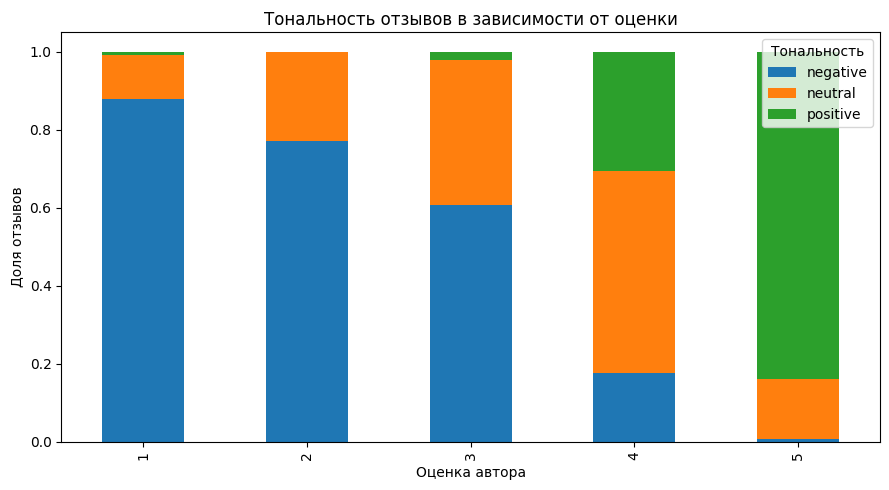

In [58]:
# Рассчитываем доли тональностей для каждой оценки
sentiment_distribution = pd.crosstab(
    rating_checked["rating"],
    rating_checked["sentiment"],
    normalize="index"
)

print("Распределение предсказанной тональности по оценкам:")
display((sentiment_distribution * 100).round(2))

# Визуализируем распределение
sentiment_distribution.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Тональность отзывов в зависимости от оценки")
plt.xlabel("Оценка автора")
plt.ylabel("Доля отзывов")
plt.legend(title="Тональность")
plt.tight_layout()
plt.show()


**Вопрос:** Какая тональность чаще всего предсказывается для каждой оценки автора? Приведите доли для одной низкой и одной высокой оценки. Что показывает рассчитанная macro-F1 и почему её нельзя напрямую сравнивать с macro-F1 на тесте RuSentiTweet как измерение изменения качества?

**Ответ:** По результатам анализа для оценок 1–3 звезды чаще всего предсказывается отрицательная тональность, для 4 звёзд — нейтральная, а для 5 звёзд — положительная.

Например, среди отзывов с одной звездой 87,94% определены как отрицательные, а среди пятизвёздочных 83,84% — как положительные. При этом для оценки 3 звезды модель также чаще предсказывает отрицательную тональность (60,64%).

Полученная macro-F1 = 0,5800 показывает степень согласованности предсказанной тональности с условными классами, сформированными по звёздам автора. Её нельзя напрямую сравнивать с macro-F1 на RuSentiTweet как показатель изменения качества, поскольку там использовалась ручная разметка тональности, а здесь — оценки пользователей, которые не всегда точно отражают эмоциональную окраску текста.

---

### **2.8. Норма расхождений**

Нужно понять, часто ли правило отбора срабатывает на обычной отложенной выборке. Рассчитаем доли `candidate` и `both` отдельно для каждой оценки автора. Для логического столбца среднее равно доле строк со значением `True`: например, 2 из 20 дают 0,10, или 10%.

Полученную таблицу `norm` будем использовать как **опорную частоту расхождений**. Она описывает наши модели на тестовых отзывах и включает как ошибки моделей, так и возможные содержательные расхождения. Это не допустимый уровень ошибок автора и не характеристика качества организации.

**Рассчитайте `norm` — средние значения `candidate` и `both` для каждой оценки автора в `rating_checked`.**

In [59]:
# Рассчитываем доли расхождений для каждой оценки
norm = (
    rating_checked
    .groupby("rating")[["candidate", "both"]]
    .mean()
)

print("Доли расхождений по оценкам:")
display(norm.round(4))

# Дополнительно представляем результаты в процентах
print("\nДоли расхождений в процентах:")
display((norm * 100).round(2))

# Общая частота расхождений
print("\nОбщие показатели:")
print(f"Candidate: {rating_checked['candidate'].mean():.2%}")
print(f"Both: {rating_checked['both'].mean():.2%}")

# Соотношение размеров групп
candidate_count = rating_checked["candidate"].sum()
both_count = rating_checked["both"].sum()

if both_count > 0:
    print(f"Группа both меньше candidate в {candidate_count / both_count:.2f} раза")


Доли расхождений по оценкам:


,candidate,both
rating,,
1,0.1064,0.0071
2,0.0417,0.0000
3,0.2766,0.2021
4,0.0118,0.0118
5,0.0116,0.0039



Доли расхождений в процентах:


,candidate,both
rating,,
1,10.64,0.71
2,4.17,0.00
3,27.66,20.21
4,1.18,1.18
5,1.16,0.39



Общие показатели:
Candidate: 3.14%
Both: 1.40%
Группа both меньше candidate в 2.25 раза


**Вопрос:** При какой оценке автора доля `candidate` максимальна? Назовите для неё доли `candidate` и `both`. Во сколько раз группа `both` меньше группы `candidate` во всём тесте? Какие отзывы более строгое правило может пропустить?

**Ответ:** Наибольшая доля расхождений обнаружена среди отзывов с оценкой 3 звезды. Для них доля `candidate` составляет 27,66%, а доля `both` — 20,21%.

Во всей тестовой выборке правило `candidate` выделило 63 отзыва (3,14%), а более строгое правило `both` — 28 отзывов (1,40%). Таким образом, вторая группа оказалась в 2,25 раза меньше первой.

Строгое правило позволяет сократить количество отзывов для ручной проверки, однако может пропустить реальные расхождения, если модель тональности определила текст как нейтральный или ошиблась в направлении эмоциональной оценки. Поэтому согласие двух моделей следует рассматривать как дополнительный критерий отбора, а не как доказательство неправильной оценки автора.

---

### **2.9. Выводы по части 2**

Приведите итоговые метрики модели звёзд на тесте и сравните их с постоянным прогнозом, указав, на какой части рассчитан каждый результат. Опишите согласованность тональности со звёздами и размер двух групп отбора. Что уже проверено численно, а что ещё нужно проверить чтением?

**Вывод:** Во второй части работы для прогнозирования оценки по тексту отзыва была выбрана модель Giga + SVM RBF с параметром C = 0,3. На тестовой выборке модель получила accuracy = 0,8205, macro-F1 = 0,5386 и MAE = 0,2183. Для сравнения, постоянный прогноз пяти звёзд на валидационной выборке показал accuracy = 0,7792, macro-F1 = 0,1752 и MAE = 0,5343. Эти результаты получены на разных выборках, поэтому сравнение является ориентировочным.

Согласованность прогнозируемой тональности с оценками пользователей составила macro-F1 = 0,5800. При анализе 2006 тестовых отзывов выявлено 63 случая расхождения минимум на две звезды, из которых 28 соответствуют правилу согласия двух моделей.

Численно подтверждено, что модели позволяют выделять потенциально противоречивые отзывы. Однако для определения содержательных расхождений необходимо дополнительно изучить тексты вручную, поскольку несовпадение прогнозов с оценкой не всегда означает ошибку автора.

---

## **Часть 3. Отзывы выбранной территории**

**Задача:** применить двух читателей к свежим отзывам выбранной территории, проверить чтением, помогает ли правило согласия находить настоящие расхождения, выделить организации, где расхождений больше обычного, сопоставить рейтинги карточек с содержанием отзывов и сравнить две территории.

Территорию выбираете вы: город по названию, прямоугольник или полигон, нарисованный на карте. В эталонном решении примером служат Фрязино и Щёлково Московской области.

### **3.1. Выбор территории и сбор отзывов**

[Сборщик отзывов Яндекс Карт](https://github.com/Alexandre77777/yandex-maps-reviews) ищет организации выбранных категорий внутри заданной территории и читает их публичные отзывы. Результат — две связанные таблицы:

| Объект | Содержание |
|---|---|
| `result.organizations` | Название, адрес, координаты, рубрики, рейтинг карточки (`rating`), число оценок (`ratings_count`) и отзывов (`reviews_count`), состояние сбора |
| `result.reviews` | Текст, дата, звёзды автора (`rating`), автор и `organization_id` |
| `result.confirmed_reviews()` | Отзывы с подтверждённым полным текстом, датой и оценкой 1–5 |
| `result.to_geopandas()` | Организации как точки в системе координат WGS84 (EPSG:4326) |

Таблицы связаны по `organization_id`. Обратите внимание: `organizations.rating` — рейтинг карточки по всем оценкам, `reviews.rating` — звёзды одного отзыва.

In [79]:
# Устанавливаем сборщик отзывов из репозитория.
%pip install -q git+https://github.com/Alexandre77777/yandex-maps-reviews.git@ce37d74b5cb76018d043dba099d612d7bc2ecd2f

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [80]:
import json  # Сохраняем GeoJSON.
import osmnx as ox  # Получаем границы из OpenStreetMap.
import folium  # Интерактивные карты.
from folium.plugins import Draw  # Рисование своей территории.
from yandex_maps_reviews import collect_area, list_categories  # Сборщик отзывов.

categories = pd.DataFrame.from_dict(list_categories(), orient='index')  # Каталог категорий.
show(categories.loc[['cafe', 'school', 'pharmacy', 'clinic', 'grocery', 'residential'], ['label', 'query']])  # Примеры категорий.
# Весь каталог: show(categories). Ключи из индекса передаются в tags.

,label,query
cafe,Кафе,кафе
school,Школы,общеобразовательные школы
pharmacy,Аптеки,аптеки
clinic,Медицинские центры,медицинские центры
grocery,Продуктовые магазины,продуктовые магазины
residential,Жилые комплексы,жилые комплексы


In [81]:
# Готовые функции: граница города и подготовка отзывов
def city_boundary(name, filename):  # Граница населённого пункта из OSM в файл GeoJSON.
    boundary = ox.geocode_to_gdf(name).to_crs(4326)  # Полигон в долготе и широте.
    Path(filename).write_text(boundary.to_json(), encoding='utf-8')  # Сохраняем для сборщика.
    show(boundary[['display_name']])  # Проверяем, что найдено.
    return boundary  # Полигон для карты.

def prepare_reviews(result):  # Подтверждённые отзывы с названием и адресом организации.
    names = result.organizations[['organization_id', 'name', 'address']].rename(columns={'name': 'organization_name', 'address': 'organization_address'})  # Подписи.
    reviews = result.confirmed_reviews().merge(names, on='organization_id', how='left', validate='many_to_one')  # Связываем таблицы.
    return reviews.reset_index(drop=True)  # Последовательные индексы.

def area_map(boundary):  # Карта найденной границы с инструментом рисования.
    west, south, east, north = boundary.total_bounds  # Охват границы.
    canvas = folium.Map(location=[(south + north) / 2, (west + east) / 2], zoom_start=12, tiles='Esri.WorldImagery')  # Центр карты на спутниковой подложке.
    folium.GeoJson(boundary[['geometry']].to_json(), name='Граница OSM', style_function=lambda _: {'color': 'yellow', 'weight': 3, 'fillOpacity': 0.05}).add_to(canvas)  # Контур территории.
    Draw(export=True, filename='drawn_area.geojson', draw_options={'circle': False, 'circlemarker': False, 'marker': False, 'polyline': False}).add_to(canvas)  # Прямоугольник и полигон.
    return canvas  # Карта для проверки.

**Как задать территорию.** Выберите **один** способ:

- **город по названию:** `city_boundary('Город, регион, Россия', 'area_a.geojson')`, затем `area_a = {'geometry': 'area_a.geojson'}`. Указывайте регион: одноимённых городов много;
- **прямоугольник:** `area_a = {'bbox': [запад, юг, восток, север]}` — долгота и широта в градусах;
- **свой полигон:** получите границу города, откройте `area_map(boundary_a)`, нарисуйте прямоугольник или многоугольник, нажмите **Export**, загрузите `drawn_area.geojson` в Colab и задайте `area_a = {'geometry': 'drawn_area.geojson'}`.

Карта помогает проверить, что выбрана нужная территория. При способе с прямоугольником получите границу города как ориентир и сопоставьте с ней указанные координаты.

**Как выбрать объём.** Для первого сбора ориентируйтесь на 3–7 минут: например, 2–3 категории, `max_orgs=3` и `max_reviews=20`. Это стартовые значения, а не требование: время зависит от числа найденных карточек и скорости сайта. `max_orgs` ограничивает число организаций на категорию, `max_reviews` — число свежих отзывов каждой организации. Для сравнения средних ниже будут использоваться организации с не менее чем `MIN_REVIEWS` отзывами; небольшая выборка подходит для знакомства с результатами, но даёт менее устойчивые выводы о территории.

Повторный запуск с теми же параметрами использует сохранённый сбор; при удалении среды Colab данные пропадают. Если сайт временно ограничит доступ, подождите перед повторным запуском.

**1. Задайте территорию `area_a`, список категорий `tags`, лимиты `max_orgs`, `max_reviews` и папку `folder_a`. Покажите территорию на карте.**

<details>
<summary><b>Пример кода</b></summary>

```python
boundary_a = city_boundary('Фрязино, Московская область, Россия', 'area_a.geojson')
area_a = {'geometry': 'area_a.geojson'}
tags = ['cafe', 'pharmacy', 'grocery', 'school']
max_orgs, max_reviews = 5, 25
folder_a = Path('reviews_a')
area_map(boundary_a)
```

</details>

In [82]:
# Первая исследуемая территория — Реутов
boundary_a = city_boundary(
    "Реутов, Московская область, Россия",
    "area_a.geojson"
)

# Используем административную границу города
area_a = {"geometry": "area_a.geojson"}

# Категории организаций
tags = ["cafe", "pharmacy", "grocery"]

# Ограничиваем объём первоначального сбора
max_orgs = 3
max_reviews = 20

# Папка для сохранения данных
folder_a = Path("reviews_reutov")

print("Территория: Реутов")
print("Категории:", tags)
print("Максимум организаций на категорию:", max_orgs)
print("Максимум отзывов на организацию:", max_reviews)

# Показываем границу города на карте
area_map(boundary_a)


,display_name
0,"Reutov, Moscow Oblast, Central Federal District, Russia"


Территория: Реутов
Категории: ['cafe', 'pharmacy', 'grocery']
Максимум организаций на категорию: 3
Максимум отзывов на организацию: 20


In [83]:
result_a = collect_area(**area_a, tags=tags, max_orgs=max_orgs, max_reviews=max_reviews, output=folder_a)  # Собираем организации и отзывы.
reviews_a = prepare_reviews(result_a)  # Подтверждённые отзывы с названиями.
print('Организаций / подтверждённых отзывов:', len(result_a.organizations), len(reviews_a))  # Объём сбора.
show(result_a.organizations[['name', 'address', 'rating', 'ratings_count', 'review_status', 'saved_reviews']])  # Состояние сбора.

Организаций / подтверждённых отзывов: 9 180


,name,address,rating,ratings_count,review_status,saved_reviews
0,Мельница,"Реутов, Юбилейный просп., 51",4.7,284,capped,20
1,Ёбидоёби,"Реутов, Носовихинское ш., 27",4.3,393,capped,20
2,Кафе-Бар Типография,"Реутов, ул. Ленина, 6Б",5.0,1703,capped,20
3,Горздрав,"Реутов, просп. Мира, 17",4.9,130,capped,20
4,Планета здоровья,"Реутов, ул. Реутовских Ополченцев, 2",5.0,788,capped,20
5,Столички,"Реутов, ул. Ленина, 22",5.0,460,capped,20
6,Дикси,"Реутов, ул. Победы, 15",4.3,1999,capped,20
7,Дикси,"Реутов, просп. Мира, 57Б",4.2,624,capped,20
8,Дикси,"Реутов, просп. Мира, 23",3.4,1166,capped,20


| Статус карточки | Что означает |
|---|---|
| `complete` | Получены все отзывы, число совпало со счётчиком страницы |
| `capped` | Достигнут лимит `max_reviews`: собраны самые свежие отзывы |
| `stalled` | Новые записи перестали поступать, полнота не подтверждена |
| `incomplete_fields` | У части записей нет обязательных полей |

Статус относится к сбору, а не к качеству организации. Поиск возвращает доступную выдачу, а не полный реестр организаций территории. [Подробнее о статусах](https://github.com/Alexandre77777/yandex-maps-reviews/blob/main/docs/USAGE.md#статусы-и-диагностика).

**Описание выборки:** укажите территорию и способ её задания, категории, дату сбора, лимиты, число организаций и подтверждённых отзывов, распределение статусов. Для каких организаций собраны не все отзывы? Можно ли по этой выборке судить обо всех организациях территории?

**Описание выборки:** Для исследования выбран город Реутов Московской области. Территория задана по административной границе, полученной из OpenStreetMap. Сбор данных выполнен 26.10.2026 с использованием Яндекс Карт.

Рассматривались три категории организаций: кафе, аптеки и продуктовые магазины. Для каждой категории установлен лимит 3 организации, для каждой организации — не более 20 отзывов.

В результате получены сведения о 9 организациях и 180 подтверждённых отзывах. Все карточки имеют статус `capped`, поскольку при сборе был достигнут установленный лимит отзывов.

Полученную выборку нельзя считать репрезентативной для всех организаций Реутова, так как она охватывает ограниченное количество объектов и преимущественно последние доступные отзывы. Результаты анализа будут характеризовать только исследованные организации и собранные сообщения.

---

### **3.2. Два читателя на новых отзывах**

Применим готовую `two_readers` к новым отзывам без дообучения. Для каждого отзыва возьмём из `norm.both` опорную частоту, соответствующую звёздам автора, и запишем её в `expected_both`.

**Как получается ожидаемое число.** *Условный пример:* в организации 10 отзывов на 5 звёзд и 5 отзывов на 3 звезды. Если опорные частоты `both` равны 1% и 10%, ожидается `10 × 0,01 + 5 × 0,10 = 0,6` случая. Ожидание может быть дробным; фактически отобранных отзывов всегда целое число. Поэтому суммируем `expected_both`, а не усредняем его.

**1. Получите `reviews_a = two_readers(reviews_a)` и добавьте столбец `expected_both` — опорную частоту для оценки автора: `reviews_a.rating.map(norm.both)`.**

**2. Выведите число отзывов в группах `candidate` и `both` и сравните наблюдаемое число случаев `both` с ожидаемым (сумма `expected_both`).**

In [84]:
# Применяем две обученные модели к отзывам Реутова
reviews_a = two_readers(reviews_a)

# Добавляем ожидаемую частоту согласованных расхождений
# на основе результатов тестовой выборки из части 2
reviews_a["expected_both"] = reviews_a["rating"].map(norm["both"])

# Подсчитываем фактические расхождения
candidate_count = int(reviews_a["candidate"].sum())
both_count = int(reviews_a["both"].sum())

# Вычисляем ожидаемое число расхождений
expected_count = reviews_a["expected_both"].sum()

print("Анализ отзывов Реутова")
print("Всего отзывов:", len(reviews_a))
print("Кандидатов (candidate):", candidate_count)
print("Согласованных расхождений (both):", both_count)

print(f"\nОжидаемое число both: {expected_count:.2f}")
print(f"Фактическое число both: {both_count}")

if expected_count > 0:
    print(
        f"Отношение фактического к ожидаемому: "
        f"{both_count / expected_count:.2f}"
    )

print("\nДоли расхождений:")
print(f"Candidate: {reviews_a['candidate'].mean():.2%}")
print(f"Both: {reviews_a['both'].mean():.2%}")

print("\nПримеры согласованных расхождений:")
show(
    reviews_a.loc[
        reviews_a["both"],
        ["organization_name", "rating", "predicted_rating", "sentiment", "text"]
    ].head(5)
)


Анализ отзывов Реутова
Всего отзывов: 180
Кандидатов (candidate): 10
Согласованных расхождений (both): 2

Ожидаемое число both: 3.25
Фактическое число both: 2
Отношение фактического к ожидаемому: 0.62

Доли расхождений:
Candidate: 5.56%
Both: 1.11%

Примеры согласованных расхождений:


,organization_name,rating,predicted_rating,sentiment,text
15,Мельница,3,1,negative,"Обычное фастфудовское кафе.\nЕсли у вас повара из СНГ, то не стоит в меню иметь пасту, пасту может качественно приготовить только итальянец, ваши повара вообще забывают о соусе, не раз такое было.\nНе понравилось то, что администратор-кассир сказал внаглую, что у них убирают сами за собой, в нормальном сервисе такое общение неприемлемо, это - выбор человека убрать ему или нет.\nЗапомните, где клиент платит деньги, он всегда прав и это - золотое правило бизнеса во всех цивильных странах, он никому ничего не обязан делать, он за это деньги платит, чтобы делали специально обученные люди."
34,Ёбидоёби,1,4,positive,"Впервые заказывала роллы, к сожалению приехали пожухленые и не очень вкусные(как будто не свежие), но отмечу быструю доставку, и вкусную сливочную колу"


**Вопрос:** Сколько случаев `both` наблюдается и сколько ожидалось по опорной частоте? Во сколько раз они различаются? Назовите две возможные причины расхождения; какие данные помогли бы отличить содержательное расхождение от ошибки модели?

**Ответ:** При анализе 180 отзывов организаций Реутова было обнаружено 2 согласованных расхождения (`both`), тогда как по опорной частоте ожидалось около 3,25. Фактическое количество оказалось примерно в 1,63 раза меньше ожидаемого.

Возможные причины различия — небольшой объём исследуемой выборки и особенности содержания отзывов выбранных организаций. Например, распределение тем и формулировок может отличаться от данных, на которых ранее проверялись модели.

Для определения причин расхождений необходим ручной анализ текстов, а также дополнительные сведения об обстоятельствах, описанных авторами. Это поможет отличить действительно противоречивое сочетание текста и оценки от неправильной интерпретации отзыва моделью.

---

### **3.3. Проверка чтением: работает ли ансамбль согласия**

Проверим рабочую гипотезу: среди отзывов, отобранных обеими моделями, доля содержательных расхождений выше, чем среди отзывов, отмеченных только моделью звёзд.

Готовая функция отбирает до 15 отзывов из каждой группы и перемешивает их. При чтении видны название организации, текст и звёзды автора, а прогнозы и группа скрыты. Сначала вы оцените содержание по единым правилам, затем раскроете группы и сравните результаты. Это помогает уменьшить влияние ожиданий от моделей.

До 30 отзывов — небольшой ручной разбор. Он позволяет увидеть типичные случаи и получить предварительные доли, но не гарантирует устойчивого различия между способами отбора.

In [85]:
# Готовые функции: выборка для чтения вслепую и раскрытие групп
def reading_sample(reviews, n=15):  # До n отзывов из каждой группы в случайном порядке.
    both = reviews.loc[reviews.both]  # Обе модели против автора.
    only = reviews.loc[reviews.candidate & ~reviews.both]  # Только модель звёзд.
    sample = pd.concat([both.sample(min(n, len(both)), random_state=SEED), only.sample(min(n, len(only)), random_state=SEED)])  # Две группы.
    return sample.sample(frac=1, random_state=SEED).reset_index(drop=True)  # Перемешиваем.

def reveal(sample, types):  # Сопоставляем ваши типы с группами.
    reading = sample.assign(type=types, group=np.where(sample.both, 'обе модели', 'только модель звёзд'))  # Добавляем тип и группу.
    reading['content'] = reading.type.isin(['знак', 'резче'])  # Настоящее расхождение текста и оценки.
    reading['model_error'] = reading.type.isin(['ошибка', 'ирония'])  # Ошибка моделей.
    show(pd.crosstab(reading.group, reading.type, margins=True))  # Типы в каждой группе.
    show(reading.groupby('group')[['content', 'model_error']].agg(['sum', 'mean']).round(2))  # Число и доля.
    return reading  # Таблица разбора.

sample_a = reading_sample(reviews_a)  # Отзывы для чтения.
show(sample_a[['organization_name', 'rating', 'text']])  # Текст и звёзды автора.

,organization_name,rating,text
0,Планета здоровья,1,Грубые фармацевты
1,Мельница,3,"Обычное фастфудовское кафе.\nЕсли у вас повара из СНГ, то не стоит в меню иметь пасту, пасту может качественно приготовить только итальянец, ваши повара вообще забывают о соусе, не раз такое было.\nНе понравилось то, что администратор-кассир сказал внаглую, что у них убирают сами за собой, в нормальном сервисе такое общение неприемлемо, это - выбор человека убрать ему или нет.\nЗапомните, где клиент платит деньги, он всегда прав и это - золотое правило бизнеса во всех цивильных странах, он никому ничего не обязан делать, он за это деньги платит, чтобы делали специально обученные люди."
2,Дикси,5,Обычный Дикси. В целом неплохой магазин.
3,Ёбидоёби,1,"Впервые заказывала роллы, к сожалению приехали пожухленые и не очень вкусные(как будто не свежие), но отмечу быструю доставку, и вкусную сливочную колу"
4,Дикси,1,не круглосуточный
5,Горздрав,1,Дорого
6,Дикси,1,"Написано круглосуточно, но бывает закрыто ночью"
7,Горздрав,1,Дорого
8,Дикси,1,Бесполезное место вроде 24/7 но работают как по кайфу \nТерриториальный видимо вообще забыл про эту точку как же бессмысленно он тут находится лучше бы открыли вторую пятерочку
9,Планета здоровья,5,Специально туда ездил за лекарствами


**1. Прочитайте каждый отзыв и определите его тип.** Запишите коды в список `types` в порядке строк таблицы (первый элемент — для строки 0).

| Код | Тип | Условный пример |
|---|---|---|
| `'знак'` | Текст и оценка противоположны | Подробная жалоба на обман с ценой — 5 звёзд; «всё понравилось» — 1 звезда |
| `'резче'` | Направление оценки совпадает, но текст заметно резче или мягче звёзд | Одни недостатки — 3 звезды |
| `'смешанный'` | Есть и плюсы, и минусы; оценка зависит от приоритетов автора | «Еда вкусная, но ждали час» — 4 звезды |
| `'ирония'` | Текст согласуется со звёздами, но ироническая фраза могла запутать модель | «Спасибо, отличная работа» о плесени в покупке — 1 звезда |
| `'ошибка'` | Текст согласуется со звёздами, явной иронии нет | «Школа топ» — 5 звёзд |
| `'не по теме'` | Текст не об организации | Сообщение о неверной точке на карте |

Сначала сопоставьте содержание со звёздами, затем выберите один код. Если текст явно расходится с оценкой, используйте `'знак'` или `'резче'`, даже если в нём есть ирония. Если есть существенные плюсы и минусы без явного противоречия оценке — `'смешанный'`. Коды `'ошибка'` и `'ирония'` означают, что по вашему прочтению текст согласуется со звёздами, хотя модели включили его в отбор.

В таблице сравнения содержательными расхождениями считаем `'знак'` и `'резче'`, ошибками моделей — `'ошибка'` и `'ирония'`. Неоднозначные случаи остаются отдельно.

In [86]:
# Результаты ручной классификации отзывов
types = [
    "ошибка",       # 0. Планета здоровья
    "резче",        # 1. Мельница
    "ошибка",       # 2. Дикси
    "смешанный",    # 3. Ёбидоёби
    "ошибка",       # 4. Дикси
    "ошибка",       # 5. Горздрав
    "ошибка",       # 6. Дикси
    "ошибка",       # 7. Горздрав
    "ошибка",       # 8. Дикси
    "ошибка"        # 9. Планета здоровья
]

print("Количество классифицированных отзывов:", len(types))
print("Количество строк в выборке:", len(sample_a))


Количество классифицированных отзывов: 10
Количество строк в выборке: 10


Теперь сопоставим вашу оценку содержания со способом отбора. `reveal` покажет число отзывов каждого типа и долю содержательных расхождений и ошибок модели внутри каждой группы.

**2. Раскройте группы:** `reading_a = reveal(sample_a, types)`.

In [87]:
# Сопоставляем ручную оценку с результатами моделей
reading_a = reveal(sample_a, types)

print("\nРезультаты ручного анализа:")
display(
    reading_a[
        ["organization_name", "rating", "type", "group", "content", "model_error"]
    ]
)


type,ошибка,резче,смешанный,All
group,,,,
обе модели,0,1,1,2
только модель звёзд,8,0,0,8
All,8,1,1,10


content      model_error     
                        sum mean         sum mean
group                                            
обе модели                1  0.5           0  0.0
только модель звёзд       0  0.0           8  1.0


Результаты ручного анализа:


,organization_name,rating,type,group,content,model_error
0,Планета здоровья,1,ошибка,только модель звёзд,False,True
1,Мельница,3,резче,обе модели,True,False
2,Дикси,5,ошибка,только модель звёзд,False,True
3,Ёбидоёби,1,смешанный,обе модели,False,False
4,Дикси,1,ошибка,только модель звёзд,False,True
5,Горздрав,1,ошибка,только модель звёзд,False,True
6,Дикси,1,ошибка,только модель звёзд,False,True
7,Горздрав,1,ошибка,только модель звёзд,False,True
8,Дикси,1,ошибка,только модель звёзд,False,True
9,Планета здоровья,5,ошибка,только модель звёзд,False,True


**Вопрос:** Сколько содержательных расхождений и ошибок модели оказалось в каждой группе? Приведите числа и доли, а также по одному примеру каждого встреченного типа с короткой цитатой. Поддерживает ли этот разбор гипотезу о пользе согласия моделей? Насколько уверенно можно обобщать результат небольшой выборки?

**Ответ:** В группе, отобранной обеими моделями, из двух отзывов один (50%) отнесён к содержательным расхождениям, а второй — к смешанным. Ошибок моделей в этой группе не выявлено. Среди восьми отзывов, отмеченных только моделью звёзд, все восемь (100%) классифицированы как ошибки модели.

Пример содержательного расхождения — отзыв о кафе «Мельница» с оценкой 3 звезды, содержащий резкую критику обслуживания: «такое общение неприемлемо». Смешанный отзыв обнаружен у «Ёбидоёби»: автор жалуется на качество роллов, но отмечает «быструю доставку». Пример ошибки модели — отзыв об аптеке «Горздрав» с оценкой 1 звезда и текстом «Дорого», который соответствует низкой оценке.

Полученные результаты предварительно поддерживают гипотезу о пользе согласия двух моделей при поиске противоречивых отзывов. Однако исследовано всего 10 сообщений, из которых только 2 попали в группу `both`. Поэтому для более надёжных выводов необходимо увеличить объём выборки и повторить ручную проверку.

---

### **3.4. Организации, где расхождений больше обычного**

> 📚 **Подсказка:** [**Занятие 1: группировка groupby**](https://colab.research.google.com/drive/1Cnp7hPUUu5dorlhPPHUeztnnoq5Z2j4W#scrollTo=baa512e4); [**GroupBy.agg**](https://pandas.pydata.org/docs/reference/api/pandas.core.groupby.DataFrameGroupBy.agg.html).

Перейдём от отдельных отзывов к организациям. Сравнение только по доле `both` зависит от состава оценок: организация с множеством трёхзвёздочных отзывов может чаще попадать в отбор уже потому, что для этой оценки опорная частота выше. Поэтому сопоставим число отобранных отзывов с ожиданием, рассчитанным по звёздам её авторов.

Учтём также общий уровень территории: умножим исходное ожидание на отношение «наблюдаемое / ожидаемое» по всем её отзывам. *Условный пример:* на территории 60 случаев при ожидаемых 40, коэффициент равен 1,5. Для организации с исходным ожиданием 0,6 скорректированное ожидание составит 0,9.

| Показатель | Как читать |
|---|---|
| `observed_both` | Фактическое число отзывов, отобранных обеими моделями |
| `expected_both_zone` | Ожидаемое число с учётом звёзд авторов и общего уровня территории |
| `relative_ratio` | Наблюдаемое / ожидаемое: 1 — на ожидаемом уровне, больше 1 — выше |
| `p_value` | Насколько необычно получить не меньше наблюдаемого числа при принятом ожидании и модели Пуассона |

Для предварительной оценки редких случаев используем `poisson.sf(observed − 1, expected)`. Например, один случай при ожидании 0,2 даёт большое отношение 5, но такое превышение ещё может возникать случайно. Малое `p_value` помогает выбрать организацию для чтения; это не вероятность ошибки автора или плохого качества организации. [Распределение Пуассона](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.poisson.html).

Ожидание оценено по данным, отзывы одной организации могут быть зависимы, а проверок сразу много. Здесь `p_value` используется как приближённый ориентир для разбора. Для подтверждённого статистического вывода потребуются проверка предположений и учёт [множественных проверок](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.false_discovery_control.html).

Функция `organization_summary` сгруппирует отзывы по организации и присоединит сведения её карточки. На выходе будет одна строка на организацию: объём выборки, средние оценки, доли и показатели отбора.

**1. Допишите функцию `organization_summary`.** В `agg` добавьте средний прогноз звёзд (`mean_predicted_stars`) и долю отрицательной тональности (`negative_share`, среднее столбца `negative`). В конце рассчитайте разницу рейтинга карточки (`rating` из таблицы организаций) со средними звёздами собранных отзывов и со средним прогнозом — она понадобится в 3.5.

In [88]:
from scipy.stats import poisson

def organization_summary(reviews, organizations):
    # Группируем отзывы по организациям
    summary = reviews.groupby("organization_id").agg(
        analyzed_reviews=("text", "size"),
        mean_review_stars=("rating", "mean"),
        mean_predicted_stars=("predicted_rating", "mean"),
        negative_share=("negative", "mean"),
        observed_both=("both", "sum"),
        expected_both=("expected_both", "sum")
    ).astype(float)

    # Корректируем ожидание с учётом всей территории
    zone_ratio = (
        summary["observed_both"].sum()
        / summary["expected_both"].sum()
    )

    summary["expected_both_zone"] = (
        summary["expected_both"] * zone_ratio
    )

    # Сравниваем наблюдаемое количество с ожидаемым
    summary["relative_ratio"] = (
        summary["observed_both"]
        / summary["expected_both_zone"].replace(0, np.nan)
    )

    # Рассчитываем предварительный статистический показатель
    summary["p_value"] = poisson.sf(
        summary["observed_both"] - 1,
        summary["expected_both_zone"]
    )

    # Объединяем результаты с карточками организаций
    result = organizations.merge(
        summary,
        left_on="organization_id",
        right_index=True
    )

    # Разница рейтинга карточки и средних оценок
    result["card_minus_stars"] = (
        result["rating"] - result["mean_review_stars"]
    )

    # Разница рейтинга карточки и прогноза модели
    result["card_minus_texts"] = (
        result["rating"] - result["mean_predicted_stars"]
    )

    return result


**2. Получите `org_a = organization_summary(reviews_a, result_a.organizations)` и выведите пять организаций с наименьшим `p_value`: название, категорию (`found_by`), число отзывов, наблюдаемое и ожидаемое число случаев, `p_value`.**

In [89]:
# Создаём сводку по организациям Реутова
org_a = organization_summary(
    reviews_a,
    result_a.organizations
)

# Выбираем пять организаций с наименьшим p-value
top_orgs = org_a.sort_values("p_value").head(5)

columns = [
    "name",
    "found_by",
    "analyzed_reviews",
    "observed_both",
    "expected_both_zone",
    "relative_ratio",
    "p_value"
]

print("Организации с наиболее заметными расхождениями:")
display(top_orgs[columns].round(4))

print("\nКоличество организаций с p-value < 0.05:")
print((org_a["p_value"] < 0.05).sum())


Организации с наиболее заметными расхождениями:


,name,found_by,analyzed_reviews,observed_both,expected_both_zone,relative_ratio,p_value
1,Ёбидоёби,[cafe],20.0,1.0,0.0674,14.8346,0.0652
0,Мельница,[cafe],20.0,1.0,0.5415,1.8468,0.4181
2,Кафе-Бар Типография,[cafe],20.0,0.0,0.0515,0.0000,1.0000
3,Горздрав,[pharmacy],20.0,0.0,0.1852,0.0000,1.0000
4,Планета здоровья,[pharmacy],20.0,0.0,0.1879,0.0000,1.0000



Количество организаций с p-value < 0.05:
0


**3. Прочитайте отзывы с `both = True` у первой организации списка: текст, звёзды автора, прогноз звёзд и тональность.**

In [90]:
# Выбираем организацию с минимальным p-value
first_org = org_a.sort_values("p_value").iloc[0]

print("Организация:", first_org["name"])
print("Наблюдаемое число both:", int(first_org["observed_both"]))
print("Ожидаемое число:", round(first_org["expected_both_zone"], 4))
print("p-value:", round(first_org["p_value"], 4))

# Отбираем её отзывы с согласованными расхождениями
org_reviews = reviews_a.loc[
    (reviews_a["organization_id"] == first_org["organization_id"])
    & (reviews_a["both"])
]

print("\nОтзывы с both = True:")

show(
    org_reviews[
        ["text", "rating", "predicted_rating", "sentiment"]
    ].reset_index(drop=True)
)


Организация: Ёбидоёби
Наблюдаемое число both: 1
Ожидаемое число: 0.0674
p-value: 0.0652

Отзывы с both = True:


,text,rating,predicted_rating,sentiment
0,"Впервые заказывала роллы, к сожалению приехали пожухленые и не очень вкусные(как будто не свежие), но отмечу быструю доставку, и вкусную сливочную колу",1,4,positive


**Вопрос:** Сколько организаций имеют `p_value < 0,05` в предварительном расчёте? Для первой организации приведите наблюдаемое и ожидаемое число и объясните прочитанные отзывы. Какие возможные причины превышения они показывают? Почему одного отношения 5 при наблюдаемом 1 и ожидаемом 0,2 недостаточно для уверенного вывода?

**Ответ:** По результатам анализа ни у одной из девяти организаций значение p-value не оказалось меньше 0,05.

Наименьшее значение получено для «Ёбидоёби»: обнаружено одно согласованное расхождение при ожидаемом количестве 0,0674 (p-value = 0,0652).

В отзыве с оценкой 1 звезда автор жалуется на качество роллов, но одновременно отмечает быструю доставку и вкусную колу. Модель предсказала 4 звезды и положительную тональность, вероятно, уделив больше внимания положительным фрагментам. Поэтому выявленное расхождение может объясняться ошибкой интерпретации смешанного отзыва, а не неправильной оценкой автора.

Даже если фактическое число случаев превышает ожидаемое в пять раз, например 1 против 0,2, этого недостаточно для уверенного вывода. При малом ожидаемом количестве единичное событие может возникнуть случайно. Для более надёжной оценки необходимо увеличить выборку и проверить устойчивость результатов.

---

### **3.5. Рейтинг карточки и содержание отзывов**

У организации есть три разные сводки: рейтинг карточки, средние звёзды собранных отзывов и средний прогноз по их текстам. Рейтинг карточки учитывает другой состав оценок, включая давние и без текста; наш сбор ограничен свежими отзывами. Сравнение покажет, насколько эти источники согласуются, и поможет выбрать случаи для чтения.

`card_minus_stars` — рейтинг карточки минус средние звёзды собранных отзывов; `card_minus_texts` — рейтинг карточки минус средний прогноз. Положительная разность означает, что рейтинг карточки выше соответствующей средней. *Условный пример:* карточка 4,5, свежие отзывы в среднем 3,5 — разность равна +1 звезде.

Чтобы одна-две записи не определяли среднюю, сравнивайте организации с не менее чем `MIN_REVIEWS` отзывами. Этот порог ограничивает самые малые выборки, но сам по себе не гарантирует точность.

**1. Задайте `MIN_REVIEWS` (например, 10) и выведите описательную статистику `card_minus_stars` и `card_minus_texts` для организаций с `analyzed_reviews ≥ MIN_REVIEWS`. Рассчитайте корреляцию рейтинга карточки со средними звёздами собранных отзывов.**

In [91]:
# Минимальное число отзывов для анализа организации
MIN_REVIEWS = 10

# Оставляем организации с достаточным количеством отзывов
reliable_a = org_a.loc[
    org_a["analyzed_reviews"] >= MIN_REVIEWS
].copy()

print("Организаций для анализа:", len(reliable_a))

# Статистика различий между рейтингами
print("\nСтатистика разницы рейтингов:")
display(
    reliable_a[
        ["card_minus_stars", "card_minus_texts"]
    ].describe().round(3)
)

# Корреляция рейтинга карточки со средними звёздами
rating_correlation = reliable_a["rating"].corr(
    reliable_a["mean_review_stars"]
)

print(f"\nКорреляция рейтинга и средних звёзд: {rating_correlation:.4f}")

# Дополнительная таблица для анализа
print("\nСравнение по организациям:")
display(
    reliable_a[
        ["name", "rating", "mean_review_stars",
         "mean_predicted_stars", "card_minus_stars",
         "card_minus_texts"]
    ].round(2)
)


Организаций для анализа: 9

Статистика разницы рейтингов:


,card_minus_stars,card_minus_texts
count,9.0,9.0
mean,1.022,1.006
std,0.711,0.642
min,0.05,0.25
25%,0.7,0.45
50%,0.9,0.95
75%,1.3,1.15
max,2.3,2.05



Корреляция рейтинга и средних звёзд: 0.6149

Сравнение по организациям:


,name,rating,mean_review_stars,mean_predicted_stars,card_minus_stars,card_minus_texts
0,Мельница,4.7,4.00,3.90,0.7,0.8
1,Ёбидоёби,4.3,3.00,3.15,1.3,1.15
2,Кафе-Бар Типография,5.0,4.60,4.55,0.4,0.45
3,Горздрав,4.9,4.20,4.50,0.7,0.4
4,Планета здоровья,5.0,3.10,2.95,1.9,2.05
5,Столички,5.0,4.10,4.05,0.9,0.95
6,Дикси,4.3,2.00,2.35,2.3,1.95
7,Дикси,4.2,4.15,3.95,0.05,0.25
8,Дикси,3.4,2.45,2.35,0.95,1.05


Проверим, похожа ли разница у организаций разных категорий. `found_by` хранит список категорий, по которым найдена организация; `explode` создаёт отдельную строку для каждого элемента списка. Организация, найденная по нескольким категориям, попадёт в каждую из них.

**2. Сравните среднюю разницу `card_minus_stars` по категориям.** Сначала разверните `found_by` методом `explode`, затем рассчитайте среднюю разность и число организаций каждой категории.

In [92]:
# Разворачиваем список категорий организаций
category_data = reliable_a.explode("found_by")

# Вычисляем среднюю разницу по каждой категории
category_stats = (
    category_data
    .groupby("found_by")
    .agg(
        organizations=("organization_id", "nunique"),
        mean_difference=("card_minus_stars", "mean")
    )
    .sort_values("mean_difference", ascending=False)
)

print("Разница рейтингов по категориям:")
display(category_stats.round(3))


Разница рейтингов по категориям:


,organizations,mean_difference
found_by,,
pharmacy,3,1.167
grocery,3,1.1
cafe,3,0.8


**3. Сформулируйте две гипотезы**, объясняющие разницу между карточкой и свежими отзывами, и **проверьте одну** на своих данных.

| № | Гипотеза | Чем проверить |
|---|---|---|
| 1 | У организаций с большим количеством оценок рейтинг карточки может сильнее отличаться от среднего по последним 20 отзывам, поскольку общий рейтинг учитывает больше исторических данных | Рассчитать корреляцию между ratings_count и абсолютной величиной card_minus_stars |
| 2 | Свежие отзывы могут отражать изменения качества обслуживания, которые ещё недостаточно повлияли на общий рейтинг карточки | Сравнить средние оценки старых и новых отзывов одной организации при наличии дат и достаточного количества записей |

<details>
<summary><b>Подсказка к гипотезам</b></summary>

В таблице организаций есть `ratings_count` — число всех оценок — и `reviews_count` — число отзывов с текстом. Если многие ставят оценку без текста, доля таких оценок `1 − reviews_count / ratings_count` может быть связана с разницей. Возможно, разница больше у популярных организаций с большим `ratings_count`. Может ли влиять то, что `max_reviews` оставляет только самые свежие отзывы? Проверку можно выполнить корреляцией или сравнением групп выше и ниже медианы.

</details>

Проверка гипотезы о количестве оценок:
Корреляция Спирмена: 0.3096


,name,ratings_count,card_minus_stars,absolute_difference
6,Дикси,1999,2.3,2.3
2,Кафе-Бар Типография,1703,0.4,0.4
8,Дикси,1166,0.95,0.95
4,Планета здоровья,788,1.9,1.9
7,Дикси,624,0.05,0.05
5,Столички,460,0.9,0.9
1,Ёбидоёби,393,1.3,1.3
0,Мельница,284,0.7,0.7
3,Горздрав,130,0.7,0.7


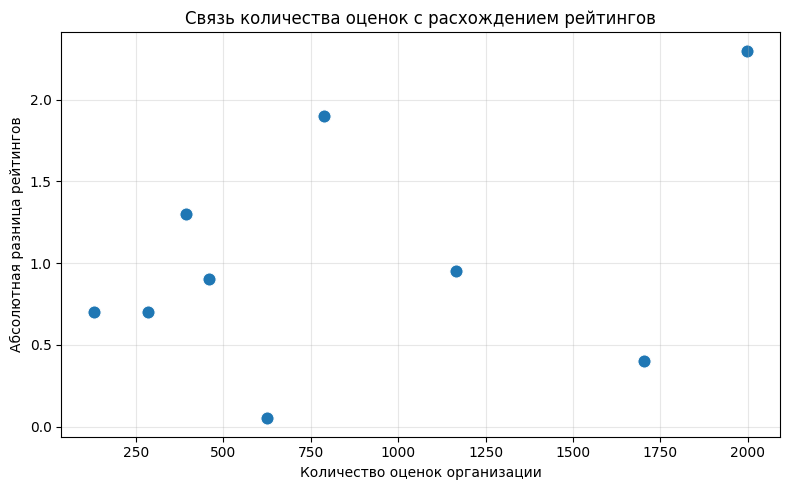

In [93]:
# Проверяем связь количества оценок с величиной расхождения

hypothesis_data = reliable_a[
    ["name", "ratings_count", "card_minus_stars"]
].copy()

# Рассчитываем абсолютную разницу рейтингов
hypothesis_data["absolute_difference"] = (
    hypothesis_data["card_minus_stars"].abs()
)

# Вычисляем ранговую корреляцию Спирмена
correlation = hypothesis_data["ratings_count"].corr(
    hypothesis_data["absolute_difference"],
    method="spearman"
)

print("Проверка гипотезы о количестве оценок:")
print(f"Корреляция Спирмена: {correlation:.4f}")

# Выводим организации для сравнения
display(
    hypothesis_data.sort_values(
        "ratings_count",
        ascending=False
    ).round(3)
)

# Визуализируем зависимость
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=hypothesis_data,
    x="ratings_count",
    y="absolute_difference",
    s=90
)

plt.title("Связь количества оценок с расхождением рейтингов")
plt.xlabel("Количество оценок организации")
plt.ylabel("Абсолютная разница рейтингов")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Гипотезы и результат проверки:**

**Гипотеза 1.** У организаций с большим количеством оценок разница между рейтингом карточки и средним значением свежих отзывов может быть выше, поскольку общий рейтинг учитывает более длительную историю оценок.

Для проверки рассчитана корреляция Спирмена между количеством оценок и абсолютной величиной расхождения. Получено значение 0,3096, что указывает на слабую положительную связь. Таким образом, гипотеза получила частичную поддержку, но убедительного подтверждения на выборке из девяти организаций нет.

**Гипотеза 2.** Различие рейтингов может быть связано с изменением качества обслуживания: последние отзывы отражают текущие проблемы, которые ещё не оказали заметного влияния на общий рейтинг карточки.

Для проверки этой гипотезы необходимо сравнить оценки за разные периоды. В рамках данной работы такая проверка не проводилась, поскольку анализ ограничен последними 20 отзывами каждой организации.

**Вопрос:** На сколько в среднем рейтинг карточки отличается от свежих отзывов с текстом? У каких категорий разница больше? Что вы посоветуете человеку, который выбирает организацию по рейтингу карточки?

**Ответ:** В исследованной выборке рейтинг карточки организации в среднем превышает оценку по свежим отзывам на 1,022 звезды. Наибольшая разница наблюдается у аптек (1,167), затем у продуктовых магазинов (1,100) и кафе (0,800).

Полученные результаты показывают, что общий рейтинг не всегда отражает содержание последних отзывов. При выборе организации рекомендуется учитывать не только среднюю оценку карточки, но и читать свежие комментарии, обращая внимание на повторяющиеся жалобы и изменения качества обслуживания.

При этом выводы ограничены небольшим количеством исследованных организаций и отзывов.

---

### **3.6. Карты**

Карты покажут, где расположены организации с разными оценками и расхождениями. Готовая `organization_map` отображает организации с не менее чем `MIN_REVIEWS` отзывами: цвет задаёт показатель, размер точки — число отзывов, всплывающая подпись — название, адрес и численные результаты.

Передайте функции таблицу организаций, результат сбора, имя столбца, подпись шкалы, границы шкалы и палитру. [Folium: маркеры](https://python-visualization.github.io/folium/latest/user_guide/vector_layers/circle_and_circle_marker.html).

In [94]:
# Готовая функция карты организаций
import html  # Безопасные подписи.
from branca.colormap import LinearColormap  # Цветовая шкала.

def organization_map(organizations, result, metric, title, limits, palette):  # Точечная карта одного показателя.
    points = result.to_geopandas()[['organization_id', 'geometry']].merge(organizations, on='organization_id')  # Координаты и показатели.
    points = points.loc[points.analyzed_reviews >= MIN_REVIEWS]  # Только организации с достаточным числом отзывов.
    canvas = folium.Map(tiles='Esri.WorldImagery')  # Спутниковая подложка Esri.
    canvas.fit_bounds([[points.geometry.y.min(), points.geometry.x.min()], [points.geometry.y.max(), points.geometry.x.max()]], padding=(30, 30))  # Охват точек.
    colors = LinearColormap(palette, vmin=limits[0], vmax=limits[1], caption=title)  # Шкала показателя.
    for _, row in points.iterrows():  # Добавляем организации.
        popup = (f"<b>{html.escape(str(row['name']))}</b><br>{html.escape(str(row['address']))}<br>"  # Название и адрес.
                 f"Отзывов в анализе: {int(row.analyzed_reviews)}<br>"  # Объём.
                 f"Звёзды авторов / прогноз по текстам: {row.mean_review_stars:.2f} / {row.mean_predicted_stars:.2f}<br>"  # Две средние.
                 f"Рейтинг карточки: {row['rating']}<br>"  # Оценка карточки.
                 f"Обе модели против автора: {int(row.observed_both)} при ожидаемых {row.expected_both_zone:.1f} (p = {row.p_value:.3f})")  # Расхождения.
        folium.CircleMarker([row.geometry.y, row.geometry.x], radius=3 + 1.2 * np.sqrt(row.analyzed_reviews), color='white', weight=1.5,  # Размер по числу отзывов.
                            fill=True, fill_color=colors(float(np.clip(row[metric], *limits))), fill_opacity=0.85,  # Цвет по показателю.
                            popup=folium.Popup(popup, max_width=340), tooltip=html.escape(str(row['name']))).add_to(canvas)  # Подписи.
    colors.add_to(canvas)  # Легенда.
    return canvas  # Готовая карта.

**Постройте четыре карты первой территории:**

| Карта | Столбец | Шкала и палитра | Что выясняем |
|---|---|---|---|
| 1. Оценка по текстам | `mean_predicted_stars` | `(1, 5)`, `['red', 'gold', 'green']` | Как модель оценивает содержание собранных отзывов |
| 2. Звёзды авторов | `mean_review_stars` | та же | Как авторы оценили те же отзывы |
| 3. Отбор относительно ожидания | `relative_ratio` | `(0, 3)`, `['white', 'purple']` | Где правило согласия срабатывает чаще ожидаемого |
| 4. Карточка против отзывов | `card_minus_stars` | `(-1.5, 1.5)`, `['#2166ac', '#f7f7f7', '#b2182b']` | Где карточка выше (красный) или ниже (синий) свежих отзывов |

Первые две карты используют одну шкалу: красный соответствует низкой средней, зелёный — высокой. Это оценки собранных отзывов, а не итоговый вердикт об организации.

На третьей карте тёмный цвет означает большое отношение, а не доказанную аномалию. Посмотрите в подписи, сколько случаев наблюдалось и ожидалось: один случай при малом ожидании тоже может дать тёмную точку. Значения за пределами цветовой шкалы показываются крайним цветом; точные значения показателей смотрите в таблице `org_a`.

<details>
<summary><b>Пример кода</b></summary>

```python
organization_map(org_a, result_a, 'mean_predicted_stars', 'Средний прогноз звёзд по текстам', (1, 5), ['red', 'gold', 'green'])
```

</details>

**Карта 1. Оценка по текстам**

In [95]:
# Средние оценки, предсказанные моделью
map_predicted = organization_map(
    org_a,
    result_a,
    "mean_predicted_stars",
    "Средний прогноз звёзд по текстам",
    (1, 5),
    ["red", "gold", "green"]
)

display(map_predicted)


**Карта 2. Звёзды авторов**

In [96]:
# Средние оценки авторов собранных отзывов
map_reviews = organization_map(
    org_a,
    result_a,
    "mean_review_stars",
    "Средняя оценка авторов отзывов",
    (1, 5),
    ["red", "gold", "green"]
)

display(map_reviews)


**Карта 3. Отбор относительно ожидания**

In [97]:
# Отношение фактического числа расхождений к ожидаемому
map_ratio = organization_map(
    org_a,
    result_a,
    "relative_ratio",
    "Отношение наблюдаемых расхождений к ожидаемым",
    (0, 3),
    ["white", "purple"]
)

display(map_ratio)


**Карта 4. Карточка против отзывов**

In [98]:
# Разница между рейтингом карточки и средними звёздами отзывов
map_difference = organization_map(
    org_a,
    result_a,
    "card_minus_stars",
    "Разница рейтинга карточки и свежих отзывов",
    (-1.5, 1.5),
    ["#2166ac", "#f7f7f7", "#b2182b"]
)

display(map_difference)


**Вопрос:** Найдите организации, у которых различаются цвета первых двух карт, и сравните численные средние в подписях. Что означает направление разницы? Сопоставьте тёмные точки третьей карты с таблицей из 3.4: велико ли у них число случаев или только отношение? На четвёртой карте разберите две организации с заметной разницей карточки и свежих отзывов. Есть ли основания связывать её с расположением, категорией или периодом оценок?

**Ответ:** На первых двух картах распределение оценок в целом похоже, однако для некоторых организаций средние прогнозы по текстам отличаются от звёзд авторов. Например, у «Горздрава» средняя оценка отзывов составляет 4,20, а прогноз модели — 4,50. У одного из магазинов «Дикси» значения составляют 2,00 и 2,35 соответственно. Положительная разница означает, что модель оценила содержание отзывов выше, чем сами авторы.

На третьей карте выделяются «Ёбидоёби» и «Мельница». У каждой организации обнаружено только одно согласованное расхождение. Высокое относительное значение у «Ёбидоёби» связано прежде всего с малым ожидаемым количеством случаев (0,0674), а не с большим числом выявленных расхождений.

На четвёртой карте заметны «Дикси» на улице Победы, где рейтинг карточки выше среднего по свежим отзывам на 2,3 звезды, и «Планета здоровья» с разницей 1,9 звезды.

По имеющимся данным нельзя уверенно связать эти различия с расположением или категорией организации. Возможное влияние периода публикации требует отдельного анализа старых и новых отзывов. Небольшой объём выборки также ограничивает достоверность пространственных выводов.

---

### **3.7. Вторая территория: весь анализ одной функцией**

Вы прошли цепочку шагов по одной территории: сбор → подготовка отзывов → два читателя → норма → сводка по организациям. Каждый шаг уже оформлен функцией, поэтому для новой территории их достаточно вызвать по порядку. Так обученные модели превращаются в инструмент, который можно применить к любой зоне.

**1. Соберите функцию `analyze_area`** из готовых шагов. Она возвращает результат сбора, таблицу отзывов и таблицу организаций.

In [99]:
def analyze_area(area, tags, max_orgs, max_reviews, folder):
    # Собираем организации и отзывы выбранной территории
    result = collect_area(
        **area,
        tags=tags,
        max_orgs=max_orgs,
        max_reviews=max_reviews,
        output=folder
    )

    # Подготавливаем подтверждённые отзывы
    reviews = prepare_reviews(result)

    # Получаем прогнозы двух моделей
    reviews = two_readers(reviews)

    # Добавляем ожидаемую частоту расхождений
    reviews["expected_both"] = reviews["rating"].map(norm["both"])

    # Рассчитываем показатели по организациям
    organizations = organization_summary(
        reviews,
        result.organizations
    )

    return result, reviews, organizations

print("Функция analyze_area создана")


Функция analyze_area создана


**2. Проверьте функцию на первой территории:** вызовите её с параметрами из 3.1 (сбор возьмёт сохранённые данные) и убедитесь, что число случаев `both` и сумма `observed_both` совпадают с полученными ранее.

In [100]:
# Проверяем функцию на уже исследованной территории
result_a_check, reviews_a_check, org_a_check = analyze_area(
    area_a,
    tags,
    max_orgs,
    max_reviews,
    folder_a
)

print("Проверка первой территории — Реутов")

print("Всего отзывов:", len(reviews_a_check))

print("Случаев both в отзывах:",
      int(reviews_a_check["both"].sum()))

print("Случаев both в сводке организаций:",
      int(org_a_check["observed_both"].sum()))

print("\nРанее было обнаружено:",
      int(reviews_a["both"].sum()))

assert reviews_a_check["both"].sum() == org_a_check["observed_both"].sum()

print("\nПроверка успешно пройдена")


Проверка первой территории — Реутов
Всего отзывов: 180
Случаев both в отзывах: 2
Случаев both в сводке организаций: 2

Ранее было обнаружено: 2

Проверка успешно пройдена


**3. Выберите вторую территорию** — другой город, другой район того же города или территорию с другим составом организаций — и задайте её любым способом из 3.1. Используйте те же категории и лимиты, чтобы сравнение было честным. Получите `result_b, reviews_b, org_b = analyze_area(...)`.

In [101]:
# Вторая территория — Балашиха Московской области
boundary_b = city_boundary(
    "Балашиха, Московская область, Россия",
    "area_b.geojson"
)

area_b = {"geometry": "area_b.geojson"}

# Используем прежние категории и лимиты
folder_b = Path("reviews_balashikha")

print("Вторая территория: Балашиха")
print("Категории:", tags)
print("Лимиты:", max_orgs, max_reviews)

# Показываем границу территории
display(area_map(boundary_b))


,display_name
0,"Balashikha, Balashikhinsky District, Moscow Oblast, Central Federal District, Russia"


Вторая территория: Балашиха
Категории: ['cafe', 'pharmacy', 'grocery']
Лимиты: 3 20


In [102]:
# Собираем и анализируем отзывы Балашихи
result_b, reviews_b, org_b = analyze_area(
    area_b,
    tags,
    max_orgs,
    max_reviews,
    folder_b
)

print("Результаты анализа Балашихи")
print("Организаций:", len(result_b.organizations))
print("Подтверждённых отзывов:", len(reviews_b))
print("Candidate:", int(reviews_b["candidate"].sum()))
print("Both:", int(reviews_b["both"].sum()))

display(
    org_b[
        ["name", "rating", "analyzed_reviews",
         "mean_review_stars", "observed_both"]
    ].round(2)
)


Batches:   0%|          | 0/12 [00:00<?, ?it/s]

Результаты анализа Балашихи
Организаций: 9
Подтверждённых отзывов: 180
Candidate: 14
Both: 8


,name,rating,analyzed_reviews,mean_review_stars,observed_both
0,Мельница,5.0,20.0,2.80,1.0
1,Мельница,5.0,20.0,3.95,0.0
2,Мельница,4.8,20.0,3.20,2.0
3,Планета здоровья,5.0,20.0,3.80,2.0
4,Планета здоровья,5.0,20.0,2.90,0.0
5,Планета здоровья,5.0,20.0,4.50,0.0
6,Пятёрочка,4.5,20.0,2.90,0.0
7,Магнит,4.2,20.0,2.65,0.0
8,Дикси,3.8,20.0,3.75,3.0


---

### **3.8. Сравнение территорий**

Сравним доли отрицательной тональности и отобранных отзывов на двух территориях. Считаем разницу **вторая территория минус первая**: положительное число означает большую долю на второй территории. Разница 0,03 — это 3 процентных пункта, а не 3% относительного роста.

Чтобы оценить неопределённость разницы, используем **бутстреп**: многократно выбираем организации с возвращением и заново считаем показатель. Одна организация может попасть в повторную выборку несколько раз, другая — не попасть; её отзывы переносим вместе. Так учитываем, что отзывы одной организации похожи друг на друга.

Готовая `compare_zones` возвращает доли на каждой территории, разницу и границы центральных 95% бутстреп-оценок: `low_orgs`, `high_orgs` при выборе организаций и `low_rows`, `high_rows` при выборе отдельных строк.

*Условный пример:* разница 0,03, интервал от −0,02 до 0,08. Он включает ноль: полученной выборки недостаточно для уверенного вывода о направлении различия. Это не означает равенство территорий. Если весь интервал положительный или отрицательный, результат указывает на соответствующее направление при принятых условиях сравнения. Бутстреп не устраняет смещение поисковой выдачи и различия состава организаций.

In [103]:
# Готовая функция сравнения территорий
def compare_zones(first, second, column, repeats=2000):  # Разница долей двух территорий и бутстреп-интервалы.
    rng = np.random.default_rng(SEED)  # Повторяемые случайные выборки.
    def org_sums(frame):  # Сумма и число строк каждой организации.
        grouped = frame.groupby('organization_id')[column].agg(['sum', 'size'])  # Агрегаты по организациям.
        return grouped['sum'].to_numpy(float), grouped['size'].to_numpy(float)  # Числовые массивы.
    (s1, n1), (s2, n2) = org_sums(first), org_sums(second)  # Две территории.
    i1, i2 = rng.integers(0, len(s1), (repeats, len(s1))), rng.integers(0, len(s2), (repeats, len(s2)))  # Организации с возвращением.
    by_orgs = s2[i2].sum(1) / n2[i2].sum(1) - s1[i1].sum(1) / n1[i1].sum(1)  # Разница в каждой выборке.
    v1, v2 = first[column].to_numpy(float), second[column].to_numpy(float)  # Значения отдельных строк.
    by_rows = rng.choice(v2, (repeats, len(v2))).mean(1) - rng.choice(v1, (repeats, len(v1))).mean(1)  # Бутстреп по строкам.
    return pd.Series({'territory_1': s1.sum() / n1.sum(), 'territory_2': s2.sum() / n2.sum(), 'difference': s2.sum() / n2.sum() - s1.sum() / n1.sum(),
                      'low_orgs': np.percentile(by_orgs, 2.5), 'high_orgs': np.percentile(by_orgs, 97.5),
                      'low_rows': np.percentile(by_rows, 2.5), 'high_rows': np.percentile(by_rows, 97.5)})  # Итоговая строка.

**1. Сравните территории по долям `negative`, `candidate` и `both`: соберите таблицу `pd.DataFrame({column: compare_zones(reviews_a, reviews_b, column) for column in [...]}).T`.**

In [104]:
# Сравниваем Реутов и Балашиху по трём показателям
comparison_zones = pd.DataFrame({
    column: compare_zones(reviews_a, reviews_b, column)
    for column in ["negative", "candidate", "both"]
}).T

comparison_zones.index.name = "Показатель"

print("Сравнение Реутова и Балашихи:")
display(comparison_zones.round(4))

# Дополнительно показываем разницу в процентных пунктах
print("\nРазница между территориями (процентные пункты):")
display((comparison_zones[["difference"]] * 100).round(2))


Сравнение Реутова и Балашихи:


,territory_1,territory_2,difference,low_orgs,high_orgs,low_rows,high_rows
Показатель,,,,,,,
negative,0.3056,0.3778,0.0722,-0.0611,0.2056,-0.0278,0.1722
candidate,0.0556,0.0778,0.0222,-0.0333,0.0722,-0.0278,0.0722
both,0.0111,0.0444,0.0333,-0.0056,0.0722,0.0000,0.0667



Разница между территориями (процентные пункты):


,difference
Показатель,
negative,7.22
candidate,2.22
both,3.33


**2. Сравните среднюю разницу «карточка − свежие отзывы».** Передайте функции таблицы организаций с не менее чем `MIN_REVIEWS` отзывами и столбец `card_minus_stars`: у каждой организации одна строка, поэтому функция вернёт средние и интервал для их разницы.

In [105]:
# Оставляем организации с достаточным количеством отзывов
reliable_b = org_b.loc[
    org_b["analyzed_reviews"] >= MIN_REVIEWS
].copy()

# Сравниваем разницу рейтинга карточки и свежих отзывов
rating_zones_comparison = compare_zones(
    reliable_a,
    reliable_b,
    "card_minus_stars"
)

print("Сравнение расхождений рейтингов:")
print("Территория 1 — Реутов")
print("Территория 2 — Балашиха")

display(rating_zones_comparison.round(4))

print("\nСредняя разница по территориям:")
print(f"Реутов: {rating_zones_comparison['territory_1']:.3f}")
print(f"Балашиха: {rating_zones_comparison['territory_2']:.3f}")

print(
    f"Разница Балашиха − Реутов: "
    f"{rating_zones_comparison['difference']:.3f}"
)


Сравнение расхождений рейтингов:
Территория 1 — Реутов
Территория 2 — Балашиха


,0
territory_1,1.0222
territory_2,1.3167
difference,0.2944
low_orgs,-0.3556
high_orgs,0.9003
low_rows,-0.3611
high_rows,0.8889



Средняя разница по территориям:
Реутов: 1.022
Балашиха: 1.317
Разница Балашиха − Реутов: 0.294


**Вопрос:** Для каких показателей интервал `[low_orgs, high_orgs]` не включает ноль? Если таких нет, какой вывод допустим? Для доли отрицательной тональности сравните ширину интервалов `high − low` при выборе организаций и строк и объясните различие. Повторилась ли на второй территории положительная разница «карточка − свежие отзывы»?

**Ответ:** Все полученные 95%-е бутстреп-интервалы при выборке по организациям включают ноль. Следовательно, несмотря на более высокие показатели в Балашихе, имеющихся данных недостаточно для уверенного подтверждения различий между территориями.

Для отрицательной тональности разница составила 7,22 процентного пункта. Интервал при выборке организаций равен от −0,0611 до 0,2056 (ширина 0,2667), а при выборке отдельных отзывов — от −0,0278 до 0,1722 (ширина 0,2000). Более широкий интервал по организациям связан с учётом зависимости отзывов внутри одной организации.

Положительная разница между рейтингом карточки и свежими отзывами наблюдается на обеих территориях: в Реутове она составляет 1,022 звезды, в Балашихе — 1,317. Разница между территориями равна 0,294 звезды, но её бутстреп-интервал от −0,3556 до 0,9003 включает ноль. Поэтому утверждать, что это расхождение действительно больше в Балашихе, пока нельзя.

Следующая ячейка сохраняет отзывы с прогнозами и сводку по организациям первой территории в CSV и GeoJSON для работы в ГИС. Её выполнение необязательно.

In [ ]:
output = Path('reports')  # Папка результатов.
output.mkdir(exist_ok=True)  # Создаём при первом запуске.
reviews_a.to_csv(output / 'reviews_a_predictions.csv', index=False)  # Отзывы с прогнозами.
points_a = result_a.to_geopandas()[['organization_id', 'geometry']].merge(org_a, on='organization_id')  # Организации с координатами.
points_a.assign(found_by=points_a.found_by.astype(str), rubrics=points_a.rubrics.astype(str)).to_file(output / 'organizations_a.geojson', driver='GeoJSON')  # Точки для ГИС.
print('Сохранено организаций / отзывов:', len(points_a), len(reviews_a))  # Проверяем объём.

---

### **3.9. Итоговые выводы**

Сформулируйте итоговые выводы по результатам работы. Опирайтесь на таблицы, карты и прочитанные отзывы.

1. **Выборка.** Укажите территории, категории организаций, дату и объём сбора, ограничения выборки.
2. **Качество моделей.** Приведите показатели классификации тональности и прогнозирования оценок. Оцените пользу правила отбора по результатам чтения; отдельно рассмотрите согласованность прогнозов тональности со звёздами.
3. **Примеры расхождений.** Разберите две-три организации с короткими цитатами из отзывов. Объясните, где содержание расходится с оценкой и какие причины возможны; сопоставьте рейтинг карточки со свежими отзывами.
4. **Сравнение территорий.** Приведите оценку разницы и её интервал. Сформулируйте, какие различия поддерживаются полученными данными.
5. **Применение результатов.** Объясните, как результаты помогают анализировать отзывы и какие дополнительные данные нужны для более обоснованных выводов.

Различайте выявленные расхождения и предполагаемые причины. Прогнозы моделей помогают выбрать отзывы для проверки; заключение о качестве организации требует анализа самих текстов и условий сбора.

**Вывод:**

**В первой части** наилучший результат показала модель Giga + SVM RBF с параметром C = 1. На тестовой выборке она достигла macro-F1 = 0,7430 и accuracy = 0,7517.

**Во второй части** для прогнозирования оценок от 1 до 5 звёзд также была выбрана Giga + SVM RBF, но с параметром C = 0,3. На тестовых данных получены macro-F1 = 0,5386, accuracy = 0,8205 и MAE = 0,2183. Согласованность прогнозируемой тональности с оценками авторов составила macro-F1 = 0,5800. Анализ показал, что модели лучше распознают крайние оценки, а промежуточные вызывают больше затруднений.

**В третьей части** были исследованы отзывы организаций Реутова и Балашихи Московской области. Сбор выполнен 26.10.2026 по трём категориям: кафе, аптеки и продуктовые магазины. В каждом городе проанализировано 9 организаций и 180 отзывов. Выборка ограничена последними 20 отзывами на организацию и не характеризует все организации городов.

В Реутове выявлено 10 потенциальных расхождений между текстом и оценкой, из которых 2 подтверждены правилом согласия двух моделей. Ручная проверка показала одно содержательное расхождение из двух отзывов группы согласия, тогда как среди восьми отзывов, отобранных только моделью звёзд, таких случаев не выявлено. Это предварительно указывает на пользу ансамбля, но выборка слишком мала для окончательных выводов.

Например, в отзыве о кафе «Мельница» с оценкой 3 звезды содержится резкая критика обслуживания. В отзыве о «Ёбидоёби» с оценкой 1 звезда одновременно упоминаются некачественные роллы и быстрая доставка. Второй случай показывает, что расхождение прогнозов с оценкой автора может возникать из-за смешанного содержания, а не ошибки пользователя.

Рейтинги карточек организаций в среднем превышали оценки собранных свежих отзывов на 1,022 звезды в Реутове и 1,317 звезды в Балашихе. Наиболее заметные различия наблюдались у отдельных магазинов и аптек.

При сравнении территорий в Балашихе оказалась выше доля отрицательной тональности на 7,22 процентного пункта, а доля согласованных расхождений — на 3,33 процентного пункта. Однако 95%-е бутстреп-интервалы включают ноль, поэтому статистически убедительных различий между территориями не установлено.

Полученные результаты показывают, что сочетание моделей обработки текста и пространственного анализа помогает выявлять отзывы, требующие дополнительного изучения, и сопоставлять характеристики организаций. Для более надёжных выводов необходимо увеличить число организаций, собрать больше отзывов за разные периоды и провести независимую ручную проверку выявленных расхождений.